**Apprentissage supervisé - Reconnaissance d'images**
=
---
---
Arthur Calvi - Raphaël Leclercq - Clément Desodt - Xavier Jourdain

Version 1.0

**Ce notebook est situé au bout du chemin '/content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas'**

##  <span style="color:green">Libraries</span> ##
---

In [24]:
#librairies

from statistics import mean
from google.colab import drive
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import torchvision.transforms as T


import random
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import time # pour calculer des temps de calcul
from PIL import Image # pour importer et visualiser les images
import glob

try:
    if 'google.colab' in str(get_ipython()):
        from google.colab import drive
        if not os.path.exists('/content/drive'):
            drive.mount('/content/drive')
        datapath = '/content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas/Images'
    else:
        datapath = os.path.join('.', 'Images')
except:
    datapath = os.path.join('.', 'Images')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Calculs sur : {device}')
print(f'Chemin des données : {datapath}')


Calculs sur : cpu
Chemin des données : /content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas/Images


##  <span style="color:green"> 1. Données d'entrée </span> ##
---

PyTorch fournit deux puissantes méthodes : `torch.utils.data.DataLoader` et `torch.utils.data.Dataset` pour utiliser, pré-charger ainsi que préparer vos données. `Dataset` stocke les échantillons et leurs étiquettes correspondantes, et `DataLoader` créé un itérable sur le dataset pour permettre un accès facile aux échantillons.

#### Base de données maçonnerie
* Image de maçonnerie avec 2 classes [maçonnerie sans fissure (y=0) et maçonnerie fissurée (y=1)]
* Base comprenant 856 images faisant chacune 100x100 pixels

In [25]:
classe = ["0","1"]
x, y = [],[]

for c in classe:
    paths = glob.glob('/content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas/Images/'+c+'/*') #liste les chemins d'accès de tous les fichiers d'un dossier
    for p in paths:
        img = Image.open(p)
        imgarray = np.asarray(img)
        x.append(imgarray)
        y.append(int(c))

x , y = np.array(x), np.array(y)

print("=> {} images ont été chargées".format(len(y)))

=> 856 images ont été chargées


In [26]:
class Dataset:
    def __init__(self,x,y): # initialisation de la classe
        self.data = x
        self.targets = y.astype('int64')

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        # Selection de l'image
        x = self.data[index]
        # Définition d'une transformation pour les données (transformation qui pourrait inclure des rognage, des rotations, ...)
        transform = T.Compose([ T.ToTensor() ])
        return transform(x)  ,  self.targets[index]

**Question:** Réaliser une séparation des données d’entraînement - 600 images -, de validation - 128 images - et de test - 128 images - (utiliser la méthode random_split de
torch.utils.data)


In [27]:
# Création du jeu de données et découpage
dataset_images = Dataset(x,y)
train_set, val_set, test_set= random_split(dataset_images,(600,128,128))

**Question:** Visualiser des images de maçonnerie avec et sans fissure. Chaque image est stockée en array dans dataset.data (utiliser la méthode imshow de matplotlib).


Visualisons pour exemple les dix premières images de maçonnerie.

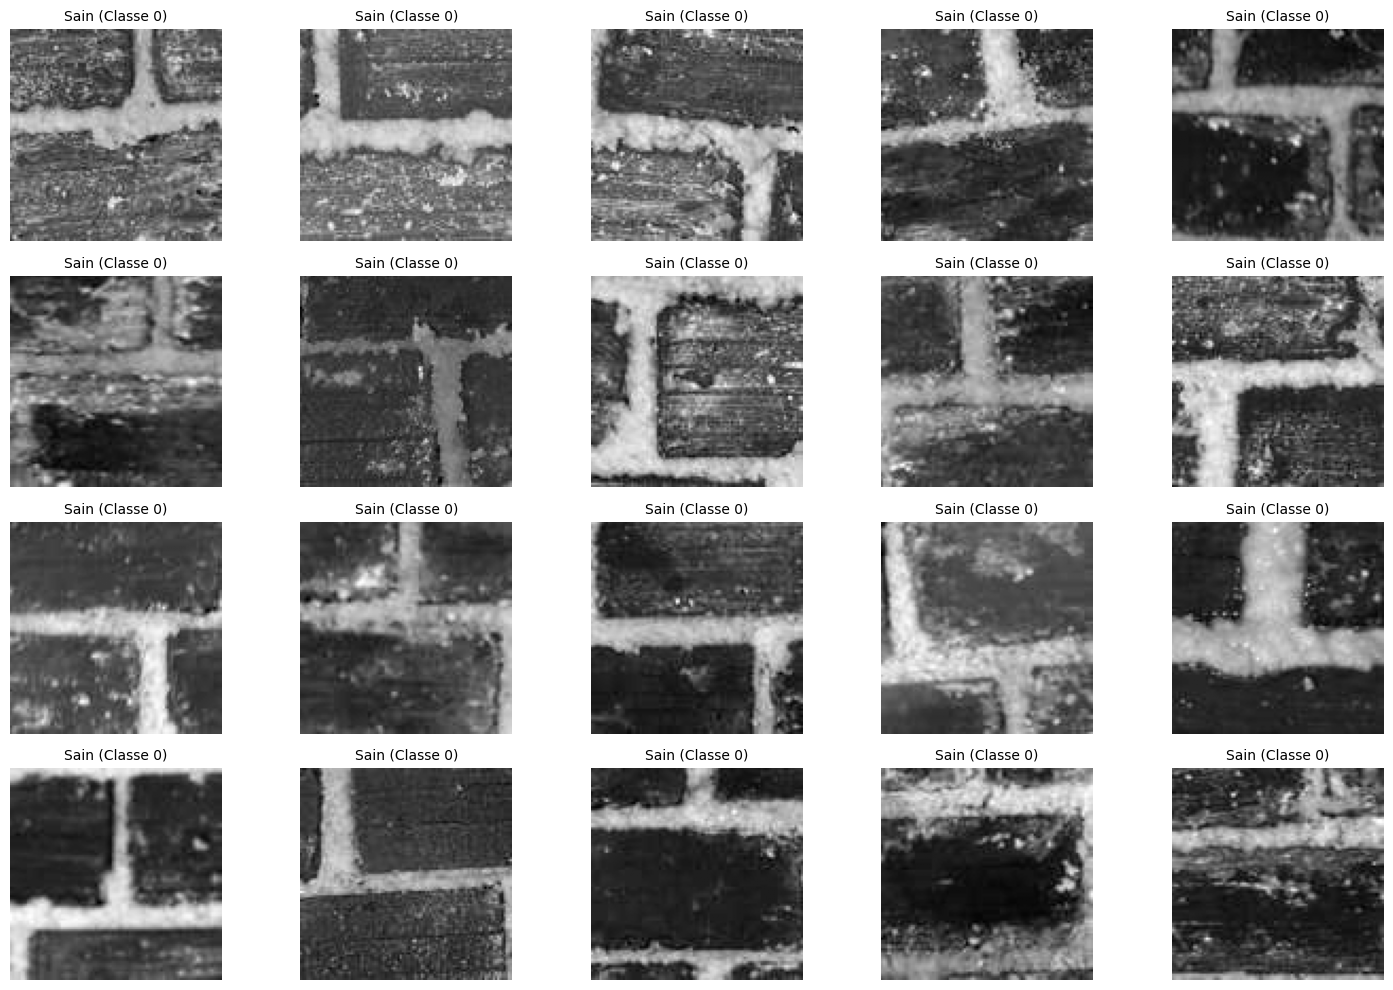

In [39]:
# --- Visualisation d'un échantillon de 20 images ---

# On crée une figure avec une grille de 4x5
fig, axes = plt.subplots(4, 5, figsize=(15, 10))
axes = axes.flatten() # Permet d'itérer facilement sur la grille en 1D

for i in range(20):
    # Affichage de l'image (en s'assurant que le format de couleur est bien géré)
    # cmap='gray' est ignoré si l'image est déjà en RGB
    axes[i].imshow(dataset_images.data[i], cmap='gray')

    # Récupération du label (0 ou 1) pour l'afficher en titre
    # On gère le cas où le label est un tenseur PyTorch
    label = dataset_images.targets[i]
    if torch.is_tensor(label):
        label = label.item()

    titre = "Fissuré" if label == 1 else "Sain"
    axes[i].set_title(f"{titre} (Classe {label})", fontsize=10)

    # On masque les axes (les graduations ne servent à rien pour des photos)
    axes[i].axis('off')

# Ajustement automatique des espaces entre les images pour éviter les chevauchements
plt.tight_layout()
plt.show()


#  <span style="color:green"> 2. Perceptron multi-couches avec PyTorch</span> ##
---

Le package `torch.nn` fournit tous les blocs de construction dont vous avez besoin pour créer votre propre réseau de neurones : couches entièrement connectées, couches convolutionnelles, etc. <br>Les couches du réseau de neurones sont initialisées dans **\_\_init\_\_**. L'architecture et les opérations sur les données d'entrée sont implémentés dans la méthode **forward**. Ci-dessous un exemple de réseau entièrement connecté à 1 couche.

*NB* : Une fonction **train** est également donnée ci-dessous pour l'entraînement du réseau.

In [29]:
#Classe d'un modèle de réseaux de neurones de type MLP = Multi-layer perceptron <=> combinaison linéaire des entrées
class Modele_MLP(nn.Module):
    # nn.Module = Module Base class for all neural network modules. Your models should also subclass this class.

    def __init__(self):
        super(Modele_MLP, self).__init__()  # interet super ici : https://devstory.net/11417/python-inheritance-polymorphism

        # Taille des images d'entrée 100*100, la taille de la couche de sortie doit correspondre au nombre de classes (ici 2)
        self.type_ = "linéaire"
        self.l1 = nn.Linear(100*100, 100)
        self.l2 = nn.Linear(100, 2)

    def forward(self, inputs):
        h = F.relu(self.l1(inputs)) # ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
        outputs = F.softmax(self.l2(h), dim=1) # Utilisation de la fonction softmax comme fonction d'activation pour la dernière couche [https://fr.wikipedia.org/wiki/Fonction_softmax]
        return outputs

In [30]:
#Fonction d'entrainement à utiliser

def train(num_epochs, batch_size, criterion, optimizer, model, train_dataset, val_dataset=None, ce=False, verbose=True):
    """
    inputs :

    num_epochs (int) : nombre d'epochs sur lequel le réseau est entrainé = nombre de fois que la base est utilisée
    batch_size (int) : nombre d'images utilisées à chaque batch (~sous-itérations)
    criterion (nn.MSELoss() or nn.CrossEntropyLoss()) : crytère utilisé pour la fonction coût
    optimizer (torch.optim.SGD, torch.optim.Adam, ...)  : algorithme d'optimisation utilisé pour l'entrainement
    model (Model or ConvNet) : Architecture du réseau de neurones
    train_dataset (torch.vision.dataset) : base de données utilisée pour l'entrainement
    val_dataset (torch.vision.dataset) : base de données utilisée pour la validation
    ce (bolean, default=False) : Vrai si la méthode d'entropie croisée est utilisée [https://fr.wikipedia.org/wiki/M%C3%A9thode_de_l%27entropie_crois%C3%A9e]

    outputs :

    tuples : (train error (float), val error (float), training time (float), nbr of epochs (int))

    """
    train_error = []
    val_error = []
    train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
    if val_dataset is not None:
        val_loader = DataLoader(val_dataset, batch_size, shuffle=True, drop_last=True)
    debut_calcul = time.perf_counter()
    # early_stop = 0

    for epoch in range(num_epochs):
        train_epoch_average_loss = 0.0
        val_epoch_average_loss = 0.0
        #train
        model.train()
        for (images,labels) in train_loader:
            if model.type_ == 'linéaire':
                #reshape the inputs from [N, img_shape, img_shape] to [N, img_shape*img_shape]
                y_pre = model(images.view(batch_size, -1))  # envoi d'une image de taille 10 * 100000
            else :
                y_pre = model(images)

            # One-hot encoding or labels so as to calculate MSE error (when CrossEntropy not used)
            if not ce:
                labels_one_hot = torch.FloatTensor(batch_size, 2)
                labels_one_hot.zero_()
                labels_one_hot.scatter_(1, labels.view(-1, 1), 1)
                labels = labels_one_hot

            loss = criterion(y_pre, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_epoch_average_loss += loss.item() * batch_size / len(train_dataset)

        train_error.append(train_epoch_average_loss)

        #validation
        if val_dataset is not None:
            model.eval()
            for (images,labels) in val_loader:
                with torch.no_grad():
                    if model.type_ == 'linéaire':
                        #reshape the inputs from [N, img_shape, img_shape] to [N, img_shape*img_shape]
                        y_pre = model(images.view(batch_size, -1))  # envoi d'une image de taille 10 * 100000
                    else :
                        y_pre = model(images)

                # One-hot encoding or labels so as to calculate MSE error (when CrossEntropy not used)
                if not ce:
                    labels_one_hot = torch.FloatTensor(batch_size, 2)
                    labels_one_hot.zero_()
                    labels_one_hot.scatter_(1, labels.view(-1, 1), 1)
                    labels = labels_one_hot

                loss = criterion(y_pre, labels)
                val_epoch_average_loss += loss.item() * batch_size / len(val_dataset)

            val_error.append(val_epoch_average_loss)

        if verbose:
            print('Epoch [{}/{}], Train Loss: {:.4f}, Val Loss: {:.4f}'.format(epoch+1, num_epochs,\
                 train_epoch_average_loss, val_epoch_average_loss))

        #early stopping (super naive):
        #if len(train_error) > 5 and (train_error[-1] - train_error[-2]) >= 0:
        #    early_stop += 1
        #else:
        #    early_stop = max(0, early_stop-1)
        #if early_stop>2:
        #    break

    fin_calcul = time.perf_counter()
    if verbose:
        print("temps de calcul ({} epochs) : {} s.".format(epoch+1,fin_calcul-debut_calcul))
    if val_dataset is not None:
        return train_error, val_error, (fin_calcul-debut_calcul) , epoch+1

    return train_error, (fin_calcul-debut_calcul) , epoch+1

## 2.1 Création et entraînement du modèle

Initialisation des paramètres, de la métrique et de l'optimisateur

In [31]:
# Création du modèle
model = Modele_MLP()
train_dataset, val_dataset, test_dataset  = train_set, val_set, test_set

# Hyperparamètres pour l'entrainement
num_epochs, batch_size = 20,10

# Fonction coût en Erreur quadratique moyenne [= mean squared error (MSE) loss function]
criterion = nn.MSELoss()

# Utilisation de la Descente de Gradient Stochastique [= Stochastic Gradient Descent (SGD)] avec un taux d'apprentissage [learning rate] de 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Utilisation de la fonction d'entrainement - def train(num_epochs, batch_size, criterion, optimizer, model, dataset, ce=False, verbose=True)
results = train(num_epochs, batch_size, criterion, optimizer, model, train_dataset, val_dataset, ce=False, verbose=True)


Epoch [1/20], Train Loss: 0.2513, Val Loss: 0.2271
Epoch [2/20], Train Loss: 0.2466, Val Loss: 0.2220
Epoch [3/20], Train Loss: 0.2475, Val Loss: 0.2240
Epoch [4/20], Train Loss: 0.2463, Val Loss: 0.2357
Epoch [5/20], Train Loss: 0.2429, Val Loss: 0.2224
Epoch [6/20], Train Loss: 0.2414, Val Loss: 0.2267
Epoch [7/20], Train Loss: 0.2400, Val Loss: 0.2306
Epoch [8/20], Train Loss: 0.2401, Val Loss: 0.2259
Epoch [9/20], Train Loss: 0.2361, Val Loss: 0.2218
Epoch [10/20], Train Loss: 0.2364, Val Loss: 0.2175
Epoch [11/20], Train Loss: 0.2371, Val Loss: 0.2411
Epoch [12/20], Train Loss: 0.2335, Val Loss: 0.2300
Epoch [13/20], Train Loss: 0.2313, Val Loss: 0.2348
Epoch [14/20], Train Loss: 0.2296, Val Loss: 0.2329
Epoch [15/20], Train Loss: 0.2278, Val Loss: 0.2329
Epoch [16/20], Train Loss: 0.2259, Val Loss: 0.2212
Epoch [17/20], Train Loss: 0.2219, Val Loss: 0.2368
Epoch [18/20], Train Loss: 0.2247, Val Loss: 0.2323
Epoch [19/20], Train Loss: 0.2257, Val Loss: 0.2265
Epoch [20/20], Train 

## 2.2 Exploitation

**Question**: Visualiser l’évolution de l’erreur sur les datasets d’entraînement et de validation en
fonction du nombre d’époques (epochs) (avec les paramètres ci-dessus). Que remarquez-vous ?


On remarque que pour le critère MSELoss, l'erreur sur le jeu d'entrainement diminue bien mais cela n'améliore pas la performance sur le jeu de données de validation. On est dans un cas de surapprentissage.

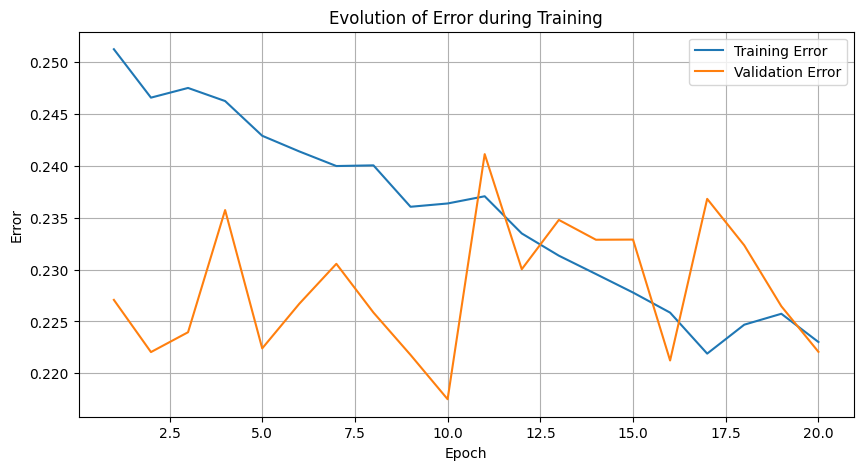

In [32]:
# Visualisation de l'évolution de l'erreur en fonction du nombre d'époques
erreur_train1, erreur_val1 = results[0], results[1]

plt.figure(figsize=(10, 5))

plt.plot(range(1, num_epochs + 1), erreur_train1, label='Training Error')
plt.plot(range(1, num_epochs + 1), erreur_val1, label='Validation Error')

plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Evolution of Error during Training')
plt.legend()
plt.grid(True)

plt.show()

**Question** : Utiliser la fonction d’évaluation pour déterminer la précision (precision), le rappel
(recall) et le F1-score (cf. Figure 4). Comparer les résultats obtenus entre les jeux de
données d’entraînement et de test (utiliser la fonction evaluation fournie dans le
notebook).

In [33]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score

def evaluation(model, dataset, batch_size, num_epochs, show=True):

    test = False
    if len(dataset) < 200:
        test = True

    val_loader = DataLoader(dataset, 10, shuffle=True, drop_last=True)
    model.eval()
    y_pred = []
    y_true = []
    for (images,labels) in val_loader:
        with torch.no_grad():
            if model.type_ == 'linéaire':
                #reshape the inputs from [N, img_shape, img_shape] to [N, img_shape*img_shape]
                y_pre = model(images.view(batch_size, -1))  # envoi d'une image de taille 10 * 100000
            else :
                y_pre = model(images)
        y_pred.extend(torch.argmax(y_pre, dim=1).tolist())
        y_true.extend(labels.tolist())

    labels = ['sain', 'fissuré']
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    recall = recall_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    if show:
        ax = sns.heatmap(cm, annot=True, fmt=".1%", cmap="viridis",  vmin=0., vmax=1., annot_kws={"size": 18},)
        ax.set_ylabel("vrai label")
        ax.set_yticks(np.arange(2)+0.5)
        ax.set_yticklabels(["sain","fissuré"])
        ax.set_xlabel("prédiction")
        ax.set_xticks(np.arange(2)+0.5)
        ax.set_xticklabels(["sain","fissuré"])
        plt.title("Matrice de confusion [% par ligne]\nmodèle {} (données {})".format(model.type_, "de test" if test else "d'entrainement"))
        # plt.savefig("Sauvegardes/modele_{}_{}data_batch_size_{}__{}_epochs_matrice_de_confusion.pdf".format(model.type_,"test" if test else "train",batch_size,num_epochs),format="pdf")
        plt.show()

        print("- Évaluation du modèle {} sur les données {} -".format(model.type_, "de test" if test else "d'entrainement"))
        print(' P = {:.2f}'.format(precision) )
        print(' R = {:.2f}'.format(recall) )
        print(' F1 = {:.2f}'.format(f1) )
        print('\n')

    return f1, precision, recall

Évaluation du jeu d'entrainement


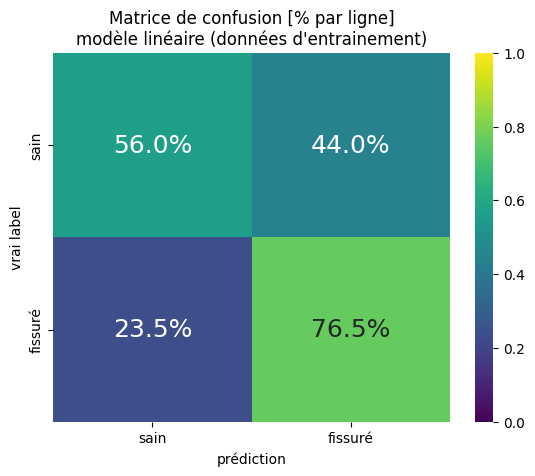

- Évaluation du modèle linéaire sur les données d'entrainement -
 P = 0.68
 R = 0.77
 F1 = 0.72


Évaluation du jeu de test


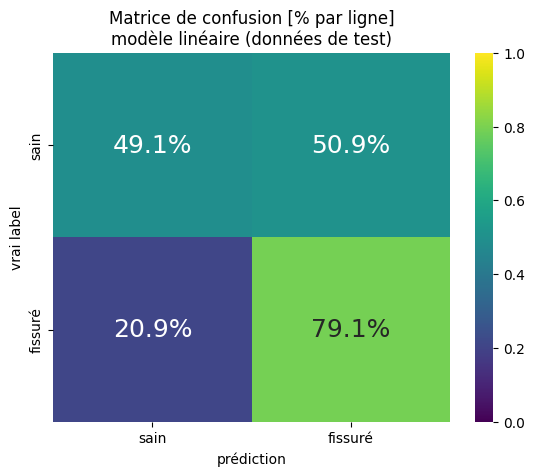

- Évaluation du modèle linéaire sur les données de test -
 P = 0.66
 R = 0.79
 F1 = 0.72




(0.7210884353741497, 0.6625, 0.7910447761194029)

In [34]:
# Précision du modèle évaluée sur le jeu de données d'entrainement
print("Évaluation du jeu d'entrainement")
evaluation(model, train_dataset, batch_size, num_epochs, show=True)

# Précision du modèle évaluée sur le jeu de données de test
print("Évaluation du jeu de test")
evaluation(model, test_dataset, batch_size, num_epochs, show=True)



On remarque que, malgré le fait d'avoir fixer les seeds à 0 pour toutes les bibliotèques, il y'a encore des variations sur les résultats de l'entrainement du modèle. On donnera donc les résultats en ordre de grandeur pour en dégager les tendances principales.

Pour le modèle étudié:

*   La précision sur le jeu d'entrainement est correct P entre 70 et 85 mais diminue sur le jeu de données de test: P entre 55 et 70
*   De même le rappel sur le jeu d'entrainement est bon: R entre 80 et 95 mais diminue grandemenent sur le jeu de données de test: R entre 70 et 80
*   Il vient que le F1-score est bon pour les données d'entrainement mais perd d'une dizaine à une vingtaine de points pour les données de test.

Ces résultats peuvent conduire à penser que le modèle est en suraprentissage, ayant des scores bon pour à l'entrainement et bien moins performant pour le test.




**Question:** (Facultatif) Montrer l’impact du nombre total d’époques (epochs) et du taux d’apprentissage sur l’erreur calculée.


In [35]:
#Vous pouvez par exemple regarder l'erreur en fonction de l'époque pour plusieurs taux d'apprentissage

erreur_train = []
erreur_val = []
learning_rate_list = np.logspace(-3,2,4)

for lr in learning_rate_list:
  model = Modele_MLP() # Model is set to zero before optimization with new lr
  optimizer = torch.optim.SGD(model.parameters(), lr=lr)
  results = train(num_epochs, batch_size, criterion, optimizer, model, train_dataset, val_dataset, ce=False, verbose=True)
  erreur_train.append(results[0])  # Append the entire train error history
  erreur_val.append(results[1])  # Append the entire validation error history


Epoch [1/20], Train Loss: 0.2492, Val Loss: 0.2325
Epoch [2/20], Train Loss: 0.2482, Val Loss: 0.2302
Epoch [3/20], Train Loss: 0.2472, Val Loss: 0.2292
Epoch [4/20], Train Loss: 0.2469, Val Loss: 0.2291
Epoch [5/20], Train Loss: 0.2461, Val Loss: 0.2257
Epoch [6/20], Train Loss: 0.2457, Val Loss: 0.2272
Epoch [7/20], Train Loss: 0.2449, Val Loss: 0.2254
Epoch [8/20], Train Loss: 0.2451, Val Loss: 0.2307
Epoch [9/20], Train Loss: 0.2447, Val Loss: 0.2305
Epoch [10/20], Train Loss: 0.2441, Val Loss: 0.2285
Epoch [11/20], Train Loss: 0.2435, Val Loss: 0.2307
Epoch [12/20], Train Loss: 0.2430, Val Loss: 0.2277
Epoch [13/20], Train Loss: 0.2431, Val Loss: 0.2283
Epoch [14/20], Train Loss: 0.2425, Val Loss: 0.2305
Epoch [15/20], Train Loss: 0.2420, Val Loss: 0.2288
Epoch [16/20], Train Loss: 0.2416, Val Loss: 0.2280
Epoch [17/20], Train Loss: 0.2407, Val Loss: 0.2316
Epoch [18/20], Train Loss: 0.2411, Val Loss: 0.2290
Epoch [19/20], Train Loss: 0.2404, Val Loss: 0.2283
Epoch [20/20], Train 

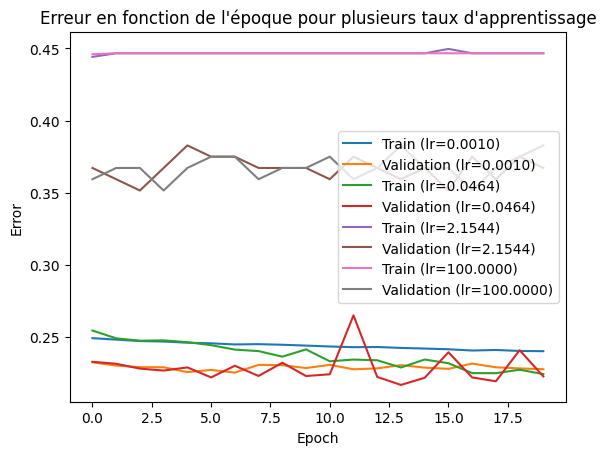

In [36]:
# Plotting the results
for i, lr in enumerate(learning_rate_list):
  plt.plot(range(num_epochs), erreur_train[i], label=f'Train (lr={lr:.4f})')
  plt.plot(range(num_epochs), erreur_val[i], label=f'Validation (lr={lr:.4f})')

plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title("Erreur en fonction de l'époque pour plusieurs taux d'apprentissage")
plt.legend()
plt.show()

On observe que le taux d'apprentissage joue un rôle important sur l'erreur. Pour un taux d'apprentissage trop faible, l'erreur diminue bien trop lentement et pour un taux d'apprentissage trop élevé, l'erreur oscille, voir reste constante autour d'une valeur plus élevée.

On observe là aussi une grande variabilité des résultats selon la simulation que l'on lance. Il est donc difficile de sortir une interprétation valable pour tous les cas. Un plus grand jeu de données aurait permis d'éviter ce problème.

# <span style="color:green"> 3. Réseau de neurones convolutif  </span>  
___

##  Première architecture de réseau de neurones convolutifs
Réseau de neurones convolutif = *(Convolutionnal Neural Network CNN)*

In [37]:
#classe d'un modèle de réseaux de neurones convolutifs avec 1 couche
class Modele_ConvNet_1(nn.Module):

    def __init__(self):
        """
        nbr_layers : int
        nbr_neurons : int
        act_fct : nn.<> (ex : nn.ReLU)
        """

        super(Modele_ConvNet_1, self).__init__()
        self.type_ = "conv"

        "solution 1 couche"
        decalage = 1
        nb_neurones_caches = 16 # Nombre de cartes de convolution
        largeur_du_noyau = 3 # doit être de la dimension des détails "intéressants" de l'image + de préférence un nombre impair (pour nous intérêt = les fissures => 3 à 5 pixels)
        nb_noyaux = int(np.ceil((100 - (largeur_du_noyau-1))/decalage)) # = nombre de noyaux dans la largeur de l'image (calcul sans padding)
        self.layers = nn.Sequential(
          nn.Conv2d(1, nb_neurones_caches, stride=decalage, kernel_size=largeur_du_noyau), # nn.Conv2d(in_channels, out_channels, kernel_size=int)
                # [https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html]
                # in_channels = nb de channels de l'image d'entrée ;
                # out_channels = nb de channels de l'image de sortie ;
                # kernel_size = taille du noyau de convolution (NB : le noyau n'est pas forcément carré => on peut mettre un tuple ex (3,4) pour un noyau rectangulaire) ;
                # VALEURS PAR DÉFAUTS NON CHANGÉES DANS CET EXEMPLE :
                # stride = 1 par défaut => nb de pixels par lesquels la fenêtre se déplace après chaque opération
                # padding = 0 par défaut => ne se promène pas sur la frontière de l'image en en dépassant de quelques pixels
                # dilation = 1 => convolution à trous => cf animation en bas de la page suivante : https://github.com/vdumoulin/conv_arithmetic/blob/master/README.md
                # bias = True => ajoute un biais d'apprentissage à la sortie
          nn.Dropout(0.25),# nn.Dropout(p) ajoute des zéros avec une probabilité p => permet une "régularisation" [https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html]
          nn.ReLU(),       # Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.Flatten(),    # nn.Flatten() => re-dimensionne le tensor en un tenseur 1D
          nn.Linear(nb_neurones_caches*nb_noyaux*nb_noyaux, 2), #nn.Linear(in_features,out_features) [https://pytorch.org/docs/stable/generated/torch.nn.Linear.html]
          )
        ###############

    def forward(self, inputs):

        outputs = self.layers(inputs)
        return F.softmax(outputs, dim=1)

**Question:** Utiliser la fonction d’entraînement train fournie dans le notebook.

1. Initialisation des paramètres, de la métrique et de l'optimisateur puis entrainement
2. Visualisation de l'évolution de l'erreur en fonction du nombre d'époques


In [40]:
# Initialisation des paramètres, de la métrique et de l'optimisateur puis entrainement

# Création du modèle
model_convnet_1 = Modele_ConvNet_1()

train_dataset, val_dataset, test_dataset  = train_set, val_set, test_set

# Hyperparamètres pour l'entrainement
num_epochs, batch_size = 20,10

# Fonction coût en Erreur quadratique moyenne [= mean squared error (MSE) loss function]
criterion = nn.MSELoss()

# Utilisation de la Descente de Gradient Stochastique [= Stochastic Gradient Descent (SGD)] avec un taux d'apprentissage [learning rate] de 0.01
optimizer = torch.optim.SGD(model_convnet_1.parameters(), lr=1e-2)

# Utilisation de la fonction d'entrainement - def train(num_epochs, batch_size, criterion, optimizer, model, dataset, ce=False, verbose=True)
results = train(num_epochs, batch_size, criterion, optimizer, model_convnet_1, train_dataset, val_dataset, ce=False, verbose=True)

Epoch [1/20], Train Loss: 0.3815, Val Loss: 0.2753
Epoch [2/20], Train Loss: 0.2421, Val Loss: 0.2163
Epoch [3/20], Train Loss: 0.2227, Val Loss: 0.2202
Epoch [4/20], Train Loss: 0.2111, Val Loss: 0.2151
Epoch [5/20], Train Loss: 0.2033, Val Loss: 0.2444
Epoch [6/20], Train Loss: 0.1970, Val Loss: 0.2225
Epoch [7/20], Train Loss: 0.1974, Val Loss: 0.2232
Epoch [8/20], Train Loss: 0.1895, Val Loss: 0.2356
Epoch [9/20], Train Loss: 0.1849, Val Loss: 0.2245
Epoch [10/20], Train Loss: 0.1770, Val Loss: 0.2224
Epoch [11/20], Train Loss: 0.1805, Val Loss: 0.2204
Epoch [12/20], Train Loss: 0.1725, Val Loss: 0.2277
Epoch [13/20], Train Loss: 0.1673, Val Loss: 0.2212
Epoch [14/20], Train Loss: 0.1634, Val Loss: 0.2449
Epoch [15/20], Train Loss: 0.1570, Val Loss: 0.2210
Epoch [16/20], Train Loss: 0.1526, Val Loss: 0.2309
Epoch [17/20], Train Loss: 0.1491, Val Loss: 0.2311
Epoch [18/20], Train Loss: 0.1455, Val Loss: 0.2246
Epoch [19/20], Train Loss: 0.1391, Val Loss: 0.2312
Epoch [20/20], Train 

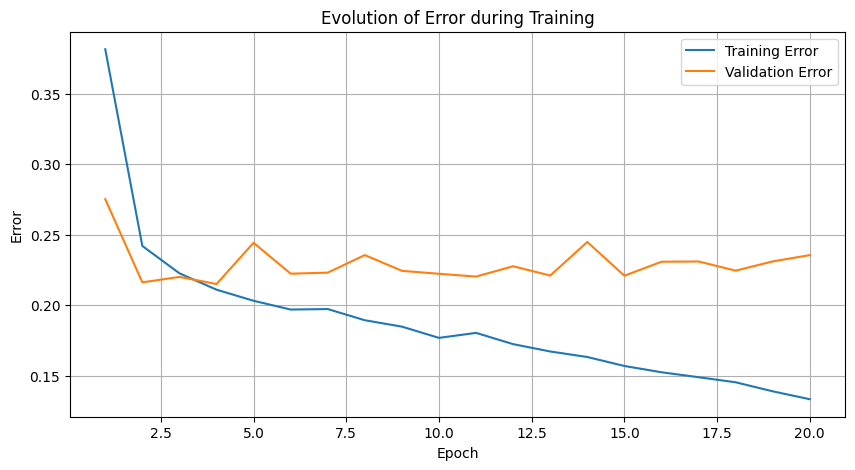

In [41]:
#Visualisation de l'évolution de l'erreur en fonction du nombre d'époques
erreur_train2, erreur_val2 = results[0], results[1]

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), erreur_train2, label='Training Error')
plt.plot(range(1, num_epochs + 1), erreur_val2, label='Validation Error')

plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Evolution of Error during Training')
plt.legend()
plt.grid(True)

plt.show()

En appliquant un principe tel que la elbow method, on peut approximer le nombre d'epoch optimal à 3 ou 4.

**Question:** Comparer les résultats entre les deux types de réseaux de neurones. Quel comportement remarquez-vous concernant l’erreur sur le dataset de validation en fonction des époques ?

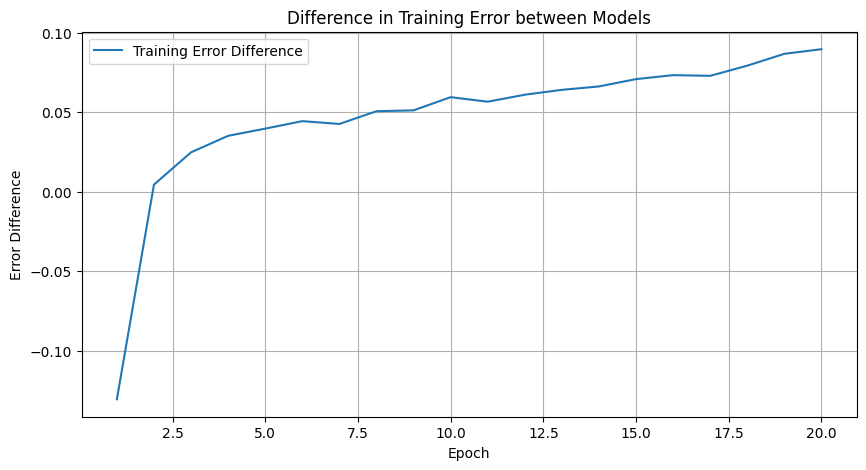

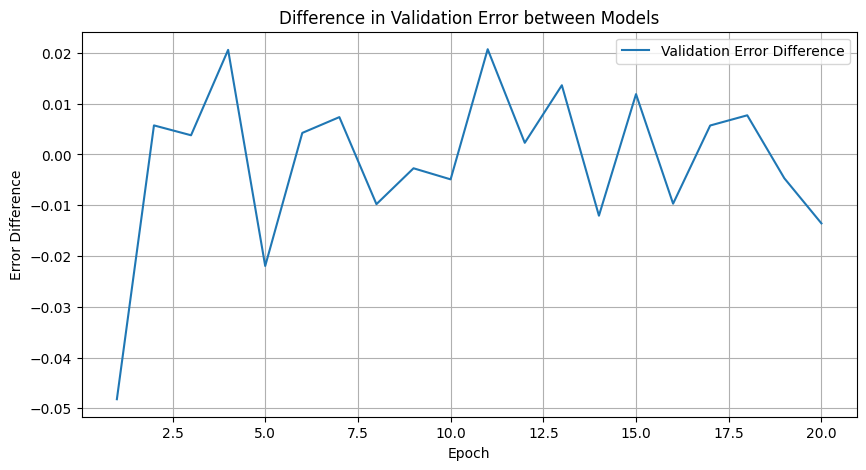

In [42]:
# Visualisation de l'écart de l'erreur en fonction du nombre d'époques
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), np.array(erreur_train1) - np.array(erreur_train2), label='Training Error Difference')
plt.xlabel('Epoch')
plt.ylabel('Error Difference')
plt.title('Difference in Training Error between Models')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(range(1, num_epochs + 1), np.array(erreur_val1) - np.array(erreur_val2), label='Validation Error Difference')
plt.xlabel('Epoch')
plt.ylabel('Error Difference')
plt.title('Difference in Validation Error between Models')
plt.legend()
plt.grid(True)
plt.show()

On observe que pour un nombre d'epoch faible, le modèle CNN est plus adapté, mais est rapidement rattrapé et dépassé par le modèle Perceptron. On peut alors favoriser le modèle convolutif dans les cas où le nombre d'epoch est supposé faible.

Évaluation du jeu d'entrainement


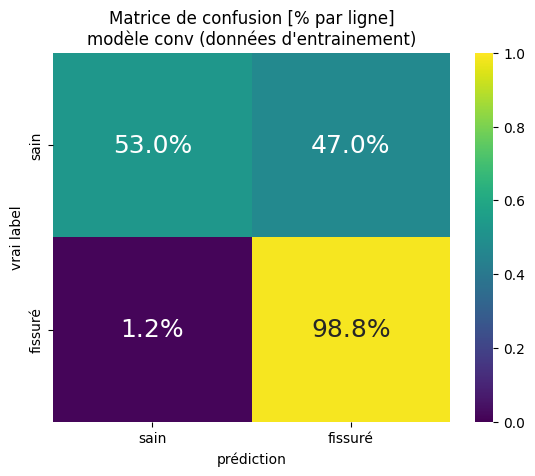

- Évaluation du modèle conv sur les données d'entrainement -
 P = 0.72
 R = 0.99
 F1 = 0.83


Évaluation du jeu de test


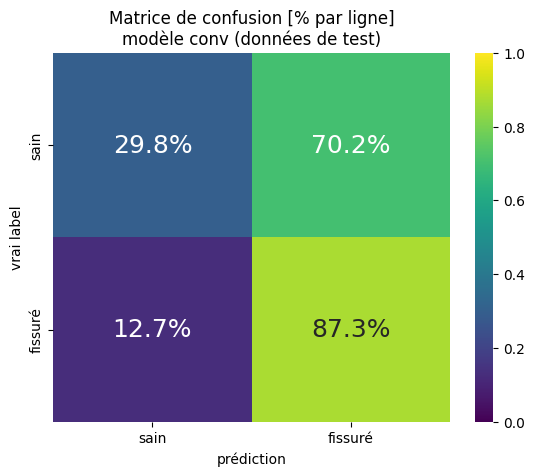

- Évaluation du modèle conv sur les données de test -
 P = 0.58
 R = 0.87
 F1 = 0.70




(0.6962025316455697, 0.5789473684210527, 0.873015873015873)

In [43]:
# Précision du modèle évaluée sur le jeu de données d'entrainement

print("Évaluation du jeu d'entrainement")
evaluation(model_convnet_1, train_dataset, batch_size, num_epochs, show=True)

# Précision du modèle évaluée sur le jeu de données de test
print("Évaluation du jeu de test")
evaluation(model_convnet_1, test_dataset, batch_size, num_epochs, show=True)


On observe que le modèle CNN identifie correctement les murs sains mais peine à détecter les fissures. Dans notre cas, il vaut mieux l'inverse...

**Question:**  Combien d’époques sont en fait nécessaires pour entraîner ce réseau de neurones sans
sur-apprentissage ?


Comme mentionné, 3 ou 4 epochs semble suffire pour fixer les paramètres du modèle.

##  Deuxième architecture de réseau de neurones convolutif (Convolutionnal Neural Network CNN)

In [44]:
#classe d'un modèle de réseaux de neurones convolutifs avec une ou plusieurs couches
class Modele_ConvNet_2(nn.Module):

    def __init__(self, nb_couches, nb_neurones, act_fct, ce=False):
        """
        nb_couches : int
        nb_neurones : int
        act_fct : nn.<> (ex : nn.ReLU)
        """

        super(Modele_ConvNet_2, self).__init__()
        self.type_ = "conv"
        self.ce = ce

        if nb_couches == 1:
            self.layers = nn.Sequential(
              nn.Conv2d(1, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Flatten(),
              nn.Linear(nb_neurones*98*98, 2),
              )

        elif nb_couches == 2:
            self.layers = nn.Sequential(
              nn.Conv2d(1, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Conv2d(nb_neurones, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Flatten(),
              nn.Linear(nb_neurones*96*96, 2),
              )

        elif nb_couches == 4:
            self.layers = nn.Sequential(
              nn.Conv2d(1, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Conv2d(nb_neurones, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Conv2d(nb_neurones, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Conv2d(nb_neurones, nb_neurones, kernel_size=3),
              nn.Dropout(0.25),
              act_fct(),
              nn.Flatten(),
              nn.Linear(nb_neurones*92*92, 2),
              )

        ###############

    def forward(self, inputs):

        outputs = self.layers(inputs)
        return F.softmax(outputs, dim=1)

Ici, on test à la main un réseau de neuronnes de 4 couches de convolution.

In [45]:
# Initialisation des paramètres, de la métrique et de l'optimisateur puis entrainement

# Création du modèle
model_convnet_2 = Modele_ConvNet_2(4,16,nn.ReLU)

train_dataset, val_dataset, test_dataset  = train_set, val_set, test_set

# Hyperparamètres pour l'entrainement
num_epochs, batch_size = 20,10

# Fonction coût en Erreur quadratique moyenne [= mean squared error (MSE) loss function]
criterion = nn.MSELoss()

# Utilisation de la Descente de Gradient Stochastique [= Stochastic Gradient Descent (SGD)] avec un taux d'apprentissage [learning rate] de 0.01
optimizer = torch.optim.SGD(model_convnet_2.parameters(), lr=1e-2)

# Utilisation de la fonction d'entrainement - def train(num_epochs, batch_size, criterion, optimizer, model, dataset, ce=False, verbose=True)
results = train(num_epochs, batch_size, criterion, optimizer, model_convnet_2, train_dataset, val_dataset, ce=False, verbose=True)

Epoch [1/20], Train Loss: 0.2504, Val Loss: 0.2201
Epoch [2/20], Train Loss: 0.2486, Val Loss: 0.2299
Epoch [3/20], Train Loss: 0.2486, Val Loss: 0.2262
Epoch [4/20], Train Loss: 0.2481, Val Loss: 0.2310
Epoch [5/20], Train Loss: 0.2480, Val Loss: 0.2312
Epoch [6/20], Train Loss: 0.2478, Val Loss: 0.2271
Epoch [7/20], Train Loss: 0.2468, Val Loss: 0.2263
Epoch [8/20], Train Loss: 0.2475, Val Loss: 0.2283
Epoch [9/20], Train Loss: 0.2468, Val Loss: 0.2331
Epoch [10/20], Train Loss: 0.2459, Val Loss: 0.2335
Epoch [11/20], Train Loss: 0.2457, Val Loss: 0.2233
Epoch [12/20], Train Loss: 0.2455, Val Loss: 0.2277
Epoch [13/20], Train Loss: 0.2414, Val Loss: 0.2290
Epoch [14/20], Train Loss: 0.2409, Val Loss: 0.2176
Epoch [15/20], Train Loss: 0.2372, Val Loss: 0.2202
Epoch [16/20], Train Loss: 0.2375, Val Loss: 0.2223
Epoch [17/20], Train Loss: 0.2349, Val Loss: 0.2265
Epoch [18/20], Train Loss: 0.2303, Val Loss: 0.2281
Epoch [19/20], Train Loss: 0.2289, Val Loss: 0.2312
Epoch [20/20], Train 

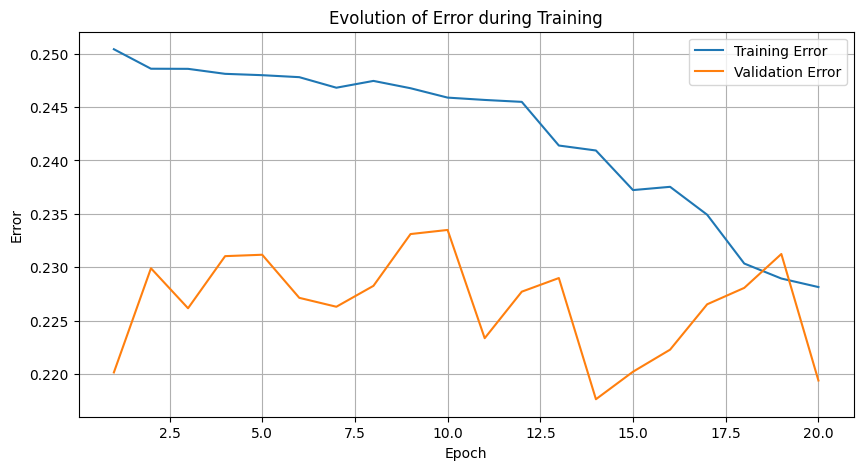

In [46]:
#Visualisation de l'évolution de l'erreur en fonction du nombre d'époques
erreur_train3, erreur_val3 = results[0], results[1]

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), erreur_train3, label='Training Error')
plt.plot(range(1, num_epochs + 1), erreur_val3, label='Validation Error')

plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Evolution of Error during Training')
plt.legend()
plt.grid(True)

plt.show()

On remarque du surapprentissage: l'erreur sur le jeu de données d'entrainement diminue mais celle sur le jeu de validation a tendance a augmenter.



Évaluation du jeu d'entrainement


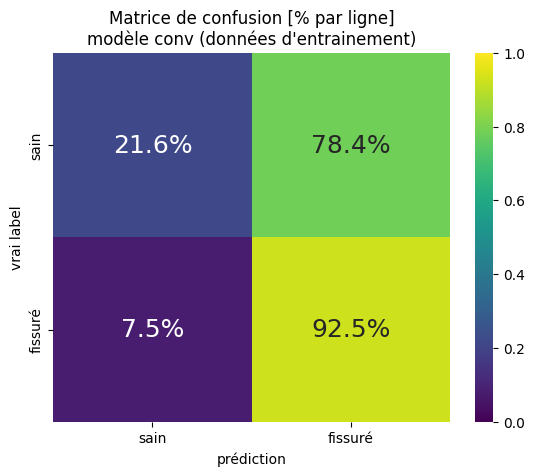

- Évaluation du modèle conv sur les données d'entrainement -
 P = 0.59
 R = 0.92
 F1 = 0.72


Évaluation du jeu de test


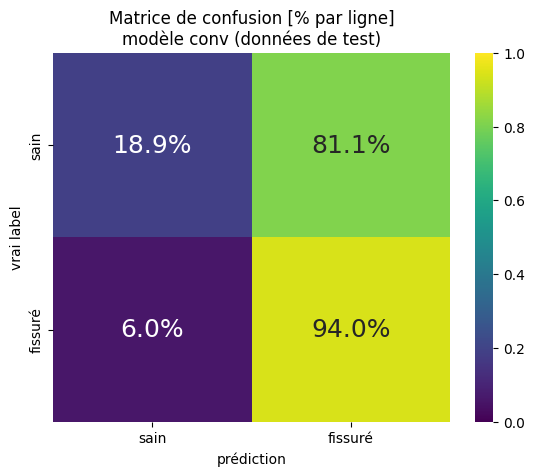

- Évaluation du modèle conv sur les données de test -
 P = 0.59
 R = 0.94
 F1 = 0.73




(0.7283236994219653, 0.5943396226415094, 0.9402985074626866)

In [47]:
# Précision du modèle évaluée sur le jeu de données d'entrainement

print("Évaluation du jeu d'entrainement")
evaluation(model_convnet_2, train_dataset, batch_size, num_epochs, show=True)

# Précision du modèle évaluée sur le jeu de données de test
print("Évaluation du jeu de test")
evaluation(model_convnet_2, test_dataset, batch_size, num_epochs, show=True)


La détection de fissure est ici performante ! Mais le modèle a encore du mal à déterminer si le mur est sain.

## 3.2 Grille de recherche (GridSearch)

Une fonction GridSearch est donnée. Elle permet de lancer plusieurs entraînement avec différents paramètres. Le dictionnaire `params` contient les paramètres à tester.

In [48]:
# Fonction GridSearch

from tqdm import tqdm
import time as tm

def GridSearch(params, model, train_dataset, test_dataset, plot=False, color=None, labels=None, ccs=None, ccm=None, save=None):
    "only compatible with ConvNet"
    """
    params  : dict
    model   : neural network architecture (ex : ConvNet)
    train_dataset : dataset pour l'entrainement
    test_dataset : dataset pour le test (et pas pour l'entrainement)
    plot    : whether to plot parallel coord or not
      color   : element of the dataframe used to colorize the plot
      labels  : elements of the dataframe used in the plot (ex : labels = ['units', 'layer', 'acc'])
      ccs     : color continuous scale
      ccm     : scale midpoint
    save    : directory to save dataframe into json
    """

    configs = []
    for bs in params['batch_size']:
        for criterion in params['criterion']:
            for lr in params['LR']:
                for units in params['units']:
                    for layer in params['layer']:
                        for activ in params['activ']:
                            configs.append({'bs':bs, 'criterion': criterion, 'lr':lr, 'units':units, 'layer':layer, 'activ':activ})


    print(f'{len(configs)} configs')
    #for i,config in tqdm(enumerate(configs)):
    for i,config in tqdm(enumerate(configs)):
        ce = bool(config['criterion'])
        model_ = model(config['layer'], config['units'], params['activ'][config['activ']], ce=ce)
        #optimizer peut être changé pour Adam
        optimizer = torch.optim.SGD(model_.parameters(), lr=config['lr'])

        start = tm.time()
        err, tps_train, epochs = train(params['num_epochs'], config['bs'], params['criterion'][config["criterion"]], optimizer, model_, train_dataset, ce=ce, verbose=False)
        end = tm.time()
        f1, prec, rec = evaluation(model_, test_dataset, params['batch_size'], params['num_epochs'], show=False)
        configs[i]['err'] = err[-1]
        configs[i]['f1'] = f1
        configs[i]['prec'] = prec
        configs[i]['rec'] = rec
        configs[i]['epochs'] = epochs
        configs[i]['time'] = end-start

    df = pd.DataFrame.from_dict(configs)

    if save is not None:
        df.to_json(save)
    if plot:
        fig = px.parallel_coordinates(df, color=color, labels=labels,
                             color_continuous_scale=ccs,
                             color_continuous_midpoint=ccm)
        fig.show()

    return df

**Question:** Appliquer la fonction GridSearch  (ne pas lancer plus de 10 configs ~ 15min) . Commenter.

In [49]:
# Définition de paramètres à utiliser avec GridSearch

# Set 1, 8 configurations
params = dict()
params['num_epochs'] = 20
params['batch_size'] = [10,100]
params['criterion'] = {0:nn.MSELoss()}
params['LR'] = [0.01]
params['units'] = [16, 32]
params['layer'] = [2, 4]
params['activ'] = {0:nn.ReLU}

In [50]:
configs = GridSearch(params, Modele_ConvNet_2, train_set, test_set, plot=True, color='f1')

8 configs


8it [1:01:50, 463.87s/it]


Le graphique montre plusieurs choses:

*   Le modèle avec le F1-score le plus élevé est celui tel que bs = 10, nb_layer = 4 et nb_units = 16.
*   Il en découle que le modèle le plus performant n'est pas nécessairement celui avec le plus de paramètres. C'est d'autant plus vrai lorsque l'on considère le temps pris par le modèle tel que bs = 100, nb_layer = 4 et nb_units = 32 (869 secondes !!).
*   Cependant, la tendance est plutôt à l'amélioration des performances avec la complexité du modèle considéré.

A noter que le F1 score est celui obtenu sur le jeu d'entrainement.


## 3.3 Utilisation d'un réseau de neurones pré-entrainé

**Question:** Récupérer les fichiers "CNN_architecture_A_batch_size_20_epochs_200" et
"CNN_architecture_B_batch_size_20_epochs_200" dans le dossier contenant le notebook. Lien de l'article : https://www.google.com/url?sa=t&rct=j&q=&esrc=s&source=web&cd=&ved=2ahUKEwjrh86FmIj9AhVVYKQEHb6TCKEQFnoECA0QAQ&url=https%3A%2F%2Fmdpi-res.com%2Fd_attachment%2Fsensors%2Fsensors-21-04929%2Farticle_deploy%2Fsensors-21-04929-v2.pdf%3Fversion%3D1626939099&usg=AOvVaw2wZ2D_lYEQeDksVHj3OkTP


### Architecture **A** de l'article "Crack Detection in Images of Masonry Using CNNs" de Hallee et al. 2021

NB : Contrairement à l'article qui travaille sur des image en couleur, les images traitées dans cette étude sont en niveau de gris afin que les calculs puissent être plus rapides

In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
#classe d'un modèle de réseaux de neurones convolutifs avec une ou plusieurs couches
class Modele_Detection2Fissures_A(nn.Module):

    def __init__(self):
        """
        nbr_layers : int
        nbr_neurons : int
        act_fct : nn.<> (ex : nn.ReLU)
        """

        super(Modele_Detection2Fissures_A, self).__init__()
        self.type_ = "conv"

        self.layers = nn.Sequential(
          #Couche#1 nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.Conv2d(1, 24, kernel_size=25, stride=1, padding="valid" ), # => 24*76*76 si zero-padding "valid" (sortie 24*100*100 si zero-padding = "same")
          #Couche#2 nn.MaxPool2D = sous-échantillonnage appliqué après une couche convolutionnelle pour réduire la taille de l'image
          nn.MaxPool2d(5, stride=2),  # => sortie 24*48*48 (24*36*36 si zeo-padding "valid")
          #Couche#3 nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.Conv2d(24, 48, kernel_size=15, stride=1, padding="valid" ), # => (sortie 48*48*48 si zero-padding = "same")
          #Couche#4 nn.MaxPool2D = sous-échantillonnage appliqué après une couche convolutionnelle pour réduire la taille de l'image
          nn.MaxPool2d(2, stride=2),  # => sortie 48*24*24
          #Couche#5 nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.Conv2d(48, 96, kernel_size=11, stride=1, padding="valid" ), # => (sortie 96*24*24 si zero-padding = "same")
          nn.Flatten(),    # nn.Flatten() => re-dimensionne le tensor en un tenseur 1D
          nn.Dropout(0.5), # nn.Dropout(p) ajoute des zéros avec une probabilité p => permet une "régularisation" [https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html]
          nn.ReLU(),       # Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.Linear(96*1*1, 2),#nn.Linear(in_features,out_features) [https://pytorch.org/docs/stable/generated/torch.nn.Linear.html]
          nn.Softmax(1)
          )

    def forward(self, inputs):

        outputs = self.layers(inputs)
        return outputs

**Question:** Déterminer les matrices de confusion pour les jeux de données d’entraînement et de
test. Comparer.

Epoch [1/20], Train Loss: 0.1001, Val Loss: 0.0801
Epoch [2/20], Train Loss: 0.1072, Val Loss: 0.0823
Epoch [3/20], Train Loss: 0.0988, Val Loss: 0.0836
Epoch [4/20], Train Loss: 0.0867, Val Loss: 0.0874
Epoch [5/20], Train Loss: 0.0888, Val Loss: 0.1298
Epoch [6/20], Train Loss: 0.0952, Val Loss: 0.0997
Epoch [7/20], Train Loss: 0.0908, Val Loss: 0.1064
Epoch [8/20], Train Loss: 0.0781, Val Loss: 0.1016
Epoch [9/20], Train Loss: 0.0748, Val Loss: 0.1001
Epoch [10/20], Train Loss: 0.0787, Val Loss: 0.0970
Epoch [11/20], Train Loss: 0.0718, Val Loss: 0.1016
Epoch [12/20], Train Loss: 0.0743, Val Loss: 0.1053
Epoch [13/20], Train Loss: 0.0597, Val Loss: 0.0996
Epoch [14/20], Train Loss: 0.0656, Val Loss: 0.0926
Epoch [15/20], Train Loss: 0.0612, Val Loss: 0.1090
Epoch [16/20], Train Loss: 0.0618, Val Loss: 0.1048
Epoch [17/20], Train Loss: 0.0669, Val Loss: 0.1078
Epoch [18/20], Train Loss: 0.0613, Val Loss: 0.1276
Epoch [19/20], Train Loss: 0.0524, Val Loss: 0.1139
Epoch [20/20], Train 

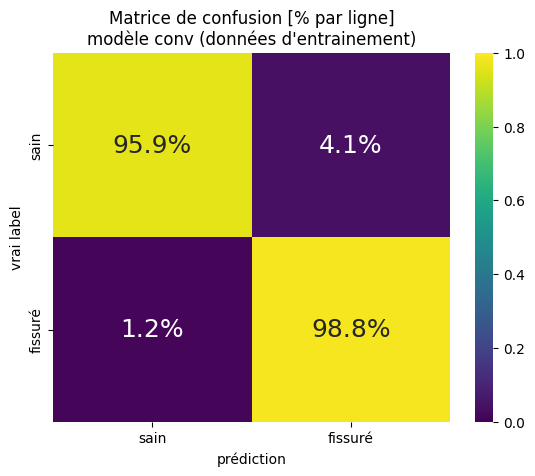

- Évaluation du modèle conv sur les données d'entrainement -
 P = 0.97
 R = 0.99
 F1 = 0.98


Évaluation du jeu de test


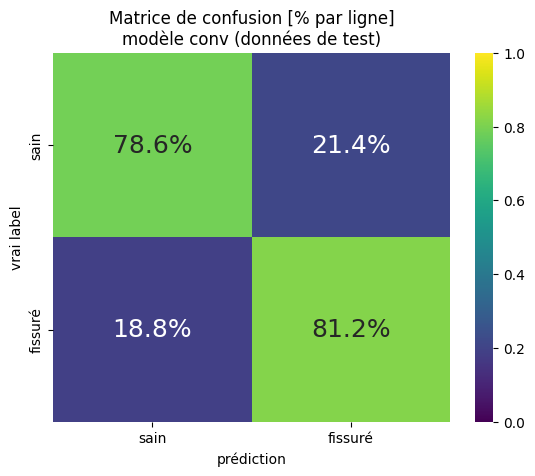

- Évaluation du modèle conv sur les données de test -
 P = 0.81
 R = 0.81
 F1 = 0.81




(0.8125, 0.8125, 0.8125)

In [61]:
# Création du modèle
model_A = Modele_Detection2Fissures_A()
datapath = '/content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas/'
# Chargement des paramètres d'un modèle [https://pytorch.org/tutorials/beginner/saving_loading_models.html]
num_epochs, batch_size = 20,10
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model_A.parameters(), lr=1e-2)
model_A.load_state_dict(torch.load(datapath + "CNN_architecture_A_batch_size_20_epochs_200"))
train(num_epochs, batch_size, criterion, optimizer, model_A, train_dataset, val_dataset, ce=False, verbose=True)

print("Évaluation du jeu d'entrainement")
evaluation(model_A, train_dataset, batch_size, num_epochs, show=True)

# Précision du modèle évaluée sur le jeu de données de test
print("Évaluation du jeu de test")
evaluation(model_A, test_dataset, batch_size, num_epochs, show=True)



Le modèle A admet de très bon résulats. Le F1-score est très haut (>90) pour l'entrainement et la validation. Le modèle est tout à fait capable de discriminer les murs sains des murs fissurés.
L'effet du pré-apprentissage est très fort.


###  Architecture B de l'article "Crack Detection in Images of Masonry Using CNNs" de Hallee et al. 2021

In [62]:
#classe d'un modèle de réseaux de neurones convolutifs avec une ou plusieurs couches
class Modele_Detection2Fissures_B(nn.Module):

    def __init__(self):
        """
        nbr_layers : int
        nbr_neurons : int
        act_fct : nn.<> (ex : nn.ReLU)
        """

        super(Modele_Detection2Fissures_B, self).__init__()
        self.type_ = "conv"

        self.layers = nn.Sequential(
          nn.Conv2d(1, 20, kernel_size=15, stride=1, padding="same" ), #Couche#1 = nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.ReLU(),       # Couche#2 = Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.Conv2d(20, 20, kernel_size=10, stride=1, padding="valid" ),  #Couche#3 = nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.ReLU(),       # Couche#4 = Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.MaxPool2d(5, stride=5), # Couche#5
          nn.Dropout(0.25), # Couche#6 = nn.Dropout(p) ajoute des zéros avec une probabilité p => permet une "régularisation" [https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html]
          nn.Conv2d(20, 40, kernel_size=5, stride=1, padding="same" ), #Couche#7 = nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.ReLU(),       # Couche#8 = Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.Conv2d(40, 40, kernel_size=2, stride=1, padding="valid" ), #Couche#9 = nn.Conv2d(in_channels, out_channels, kernel_size)
          nn.ReLU(),       # Couche#10 = Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.MaxPool2d(4, stride=4),  # Couche#11
          nn.Dropout(0.25), # Couche#12 = nn.Dropout(p) ajoute des zéros avec une probabilité p => permet une "régularisation" [https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html]
          nn.Flatten(),    # Couche#13 = nn.Flatten() => re-dimensionne le tensor en un tenseur 1D
          nn.Linear(40*4*4, 50),# Couche#14 = nn.Linear(in_features,out_features) [https://pytorch.org/docs/stable/generated/torch.nn.Linear.html]
          nn.ReLU(),       # Couche#15 = Fonction d'activation ReLU = Rectified Linear Unit function = max(0,x) <=> ReLU=0 avant x=0 ; ReLU=x après x=0
          nn.Dropout(0.5), # Couche#16 = nn.Dropout(p) ajoute des zéros avec une probabilité p => permet une "régularisation" [https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html]
          nn.Linear(50, 2),# Couche#14 = nn.Linear(in_features,out_features) [https://pytorch.org/docs/stable/generated/torch.nn.Linear.html]
          nn.Softmax(1)
          )

    def forward(self, inputs):

        outputs = self.layers(inputs)
        return outputs

**Question:** Déterminer les matrices de confusion pour les jeux de données d’entraînement et de
test. Comparer.

In [63]:
# Création du modèle
model_B = Modele_Detection2Fissures_B()
datapath = '/content/drive/MyDrive/Colab Notebooks/MSG22_ML_2025/Datas/'
# Chargement des paramètres d'un modèle [https://pytorch.org/tutorials/beginner/saving_loading_models.html]
num_epochs, batch_size = 20,10
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model_B.parameters(), lr=1e-1)
model_B.load_state_dict(torch.load(datapath + "CNN_architecture_B_batch_size_20_epochs_200"))
train(num_epochs, batch_size, criterion, optimizer, model_B, train_dataset, val_dataset, ce=False, verbose=True)


Epoch [1/20], Train Loss: 0.2503, Val Loss: 0.2190
Epoch [2/20], Train Loss: 0.2353, Val Loss: 0.2171
Epoch [3/20], Train Loss: 0.2432, Val Loss: 0.2264
Epoch [4/20], Train Loss: 0.2400, Val Loss: 0.2210
Epoch [5/20], Train Loss: 0.2383, Val Loss: 0.2228
Epoch [6/20], Train Loss: 0.2341, Val Loss: 0.2245
Epoch [7/20], Train Loss: 0.2379, Val Loss: 0.2210
Epoch [8/20], Train Loss: 0.2382, Val Loss: 0.2221
Epoch [9/20], Train Loss: 0.2385, Val Loss: 0.2195
Epoch [10/20], Train Loss: 0.2370, Val Loss: 0.2225
Epoch [11/20], Train Loss: 0.2359, Val Loss: 0.2232
Epoch [12/20], Train Loss: 0.2361, Val Loss: 0.2280
Epoch [13/20], Train Loss: 0.2306, Val Loss: 0.2327
Epoch [14/20], Train Loss: 0.2343, Val Loss: 0.2213
Epoch [15/20], Train Loss: 0.2350, Val Loss: 0.2211
Epoch [16/20], Train Loss: 0.2320, Val Loss: 0.2424
Epoch [17/20], Train Loss: 0.2306, Val Loss: 0.2145
Epoch [18/20], Train Loss: 0.2337, Val Loss: 0.2260
Epoch [19/20], Train Loss: 0.2329, Val Loss: 0.2274
Epoch [20/20], Train 

([0.25029218147198357,
  0.2352598751584689,
  0.24318955441315965,
  0.24003450547655422,
  0.23832836573322613,
  0.23406042704979582,
  0.23793256580829622,
  0.23819369499882062,
  0.23852614561716717,
  0.23704627205928164,
  0.23591235925753912,
  0.23606097723046943,
  0.23064085816343624,
  0.2342626914381981,
  0.23498322914044067,
  0.23202650969227157,
  0.23061227227250744,
  0.2337268933653831,
  0.23291699066758162,
  0.22966760508716116],
 [0.21901383181102574,
  0.21712935413233936,
  0.2263838960789144,
  0.22099714493378997,
  0.22277818876318634,
  0.22450007149018347,
  0.2209820249117911,
  0.22211468894965947,
  0.21949451765976846,
  0.22245757398195565,
  0.22322608274407685,
  0.22796344012022018,
  0.23268192308023572,
  0.22130155703052878,
  0.22114912688266486,
  0.24237641948275268,
  0.21446380415000021,
  0.22602149634622037,
  0.22735235979780555,
  0.22920418996363878],
 1225.072088297,
 20)

évaluation du jeu d'entrainement


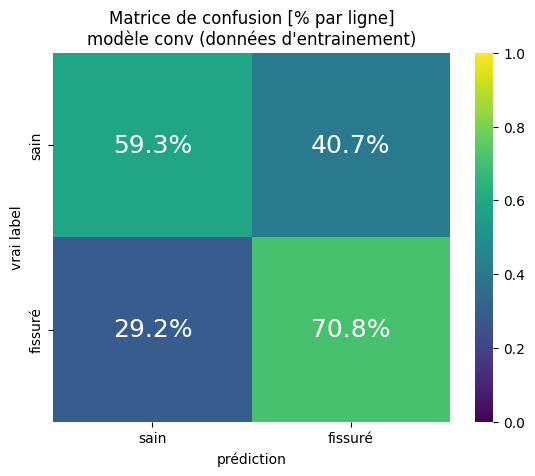

- Évaluation du modèle conv sur les données d'entrainement -
 P = 0.68
 R = 0.71
 F1 = 0.70


Évaluation du jeu de test


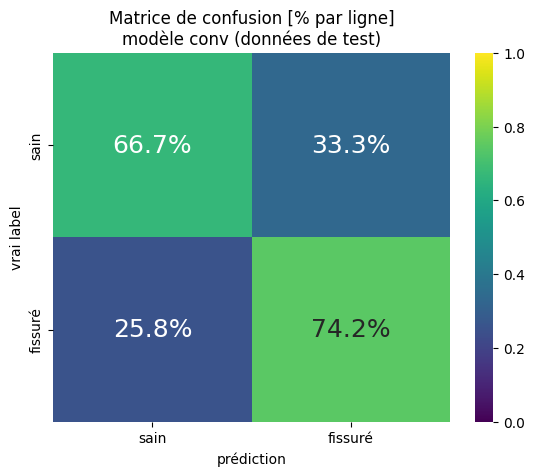

- Évaluation du modèle conv sur les données de test -
 P = 0.73
 R = 0.74
 F1 = 0.74




(0.7368421052631579, 0.7313432835820896, 0.7424242424242424)

In [64]:
# Précision du modèle évaluée sur le jeu de données d'entrainement
print("évaluation du jeu d'entrainement")
evaluation(model_B, train_dataset, batch_size, num_epochs, show=True)
# Précision du modèle évaluée sur le jeu de données de test
print("Évaluation du jeu de test")
evaluation(model_B, test_dataset, batch_size, num_epochs, show=True)

Le modèle B est performant dans la détection de fissures (précision assez élevée) mais peine beaucoup plus a classifier une image de maçonnerie saine.

## 3.4 Visualisation des filtres d'un réseau (facultatif)
---
La fonction visualisation_parametres permet de visualiser les paramètres d’un modèle convolutif et notamment les filtres des couches de convolution (NB : seule les ’faces’ supérieures des couches ayant une troisième dimension sont représentées).

**Question:** Visualiser les filtres de l’architecture A et/ou B et commenter.

In [65]:
# Visualisation des paramètres optimisés du réseau
def visualisation_parametres(dictionnaire_etat,couches):
    print("'state_dict' du modèle étudié :")
    for parametre in dictionnaire_etat:
        print(parametre,"\t",dictionnaire_etat[parametre].size())
    for couche in couches:
        tenseur_PT = dictionnaire_etat[couche]
        mini = torch.min(tenseur_PT)
        maxi = torch.max(tenseur_PT)
        nb_filtres = len(tenseur_PT)
        print("\nVisualisation de la face des {} filtres de la couche '{}'".format(nb_filtres,couche))
        nb_colonnes = int(np.sqrt(nb_filtres))
        nb_lignes = int(nb_filtres/nb_colonnes)+1
        fig = plt.figure(figsize = (20,20))
        #fig, axes = plt.subplots(nb_lignes, nb_colonnes)
        for i,filtre in enumerate(tenseur_PT):
            ax_i = fig.add_subplot(nb_lignes, nb_colonnes, i+1)
            i_col = int(np.floor(i/nb_colonnes))
            i_lig = i - i_col*nb_lignes
            sns.heatmap(filtre[0], ax=ax_i, fmt=".1f", vmin=mini, vmax=maxi, cmap="viridis")
            #axes[i_lig, i_col].set_title("filtre #"+str(i))
        plt.show()


'state_dict' du modèle étudié :
layers.0.weight 	 torch.Size([24, 1, 25, 25])
layers.0.bias 	 torch.Size([24])
layers.2.weight 	 torch.Size([48, 24, 15, 15])
layers.2.bias 	 torch.Size([48])
layers.4.weight 	 torch.Size([96, 48, 11, 11])
layers.4.bias 	 torch.Size([96])
layers.8.weight 	 torch.Size([2, 96])
layers.8.bias 	 torch.Size([2])

Visualisation de la face des 24 filtres de la couche 'layers.0.weight'


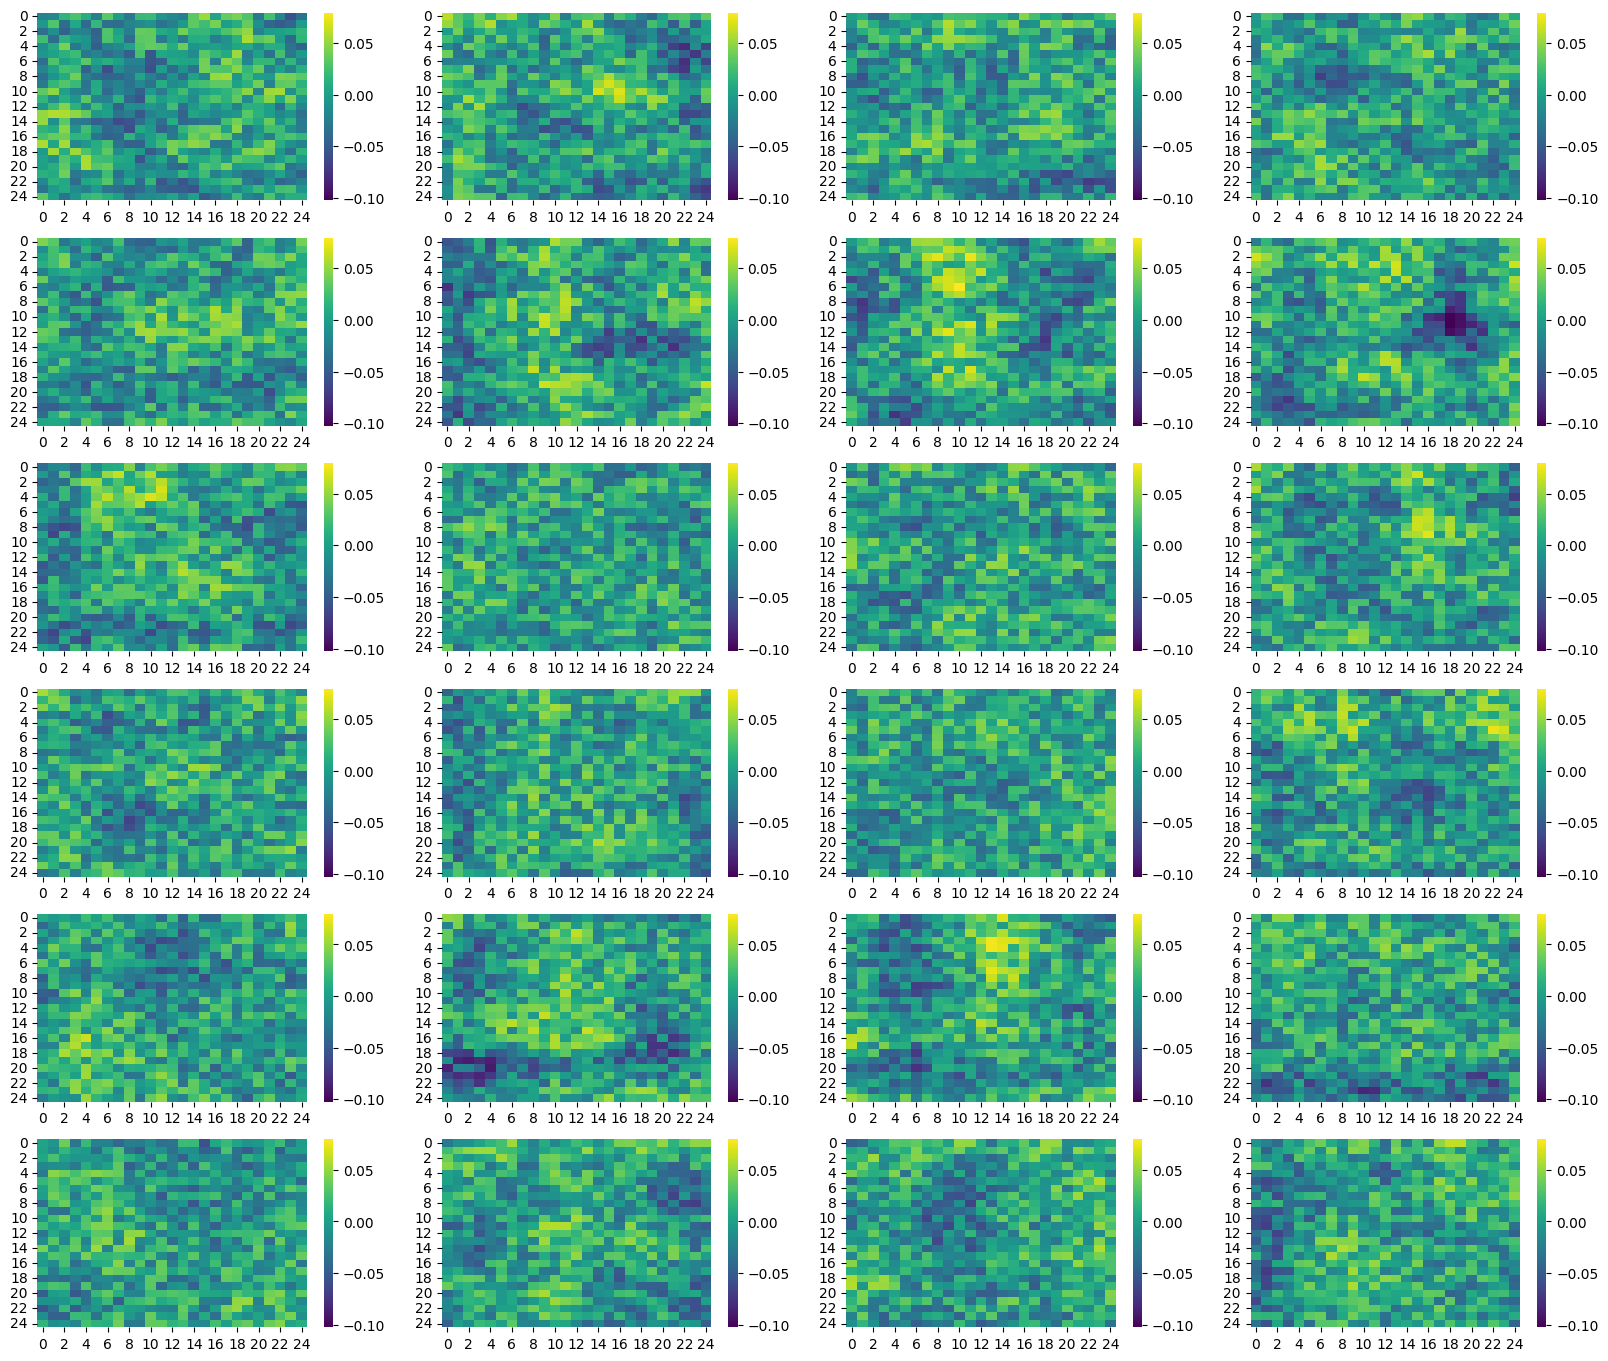


Visualisation de la face des 48 filtres de la couche 'layers.2.weight'


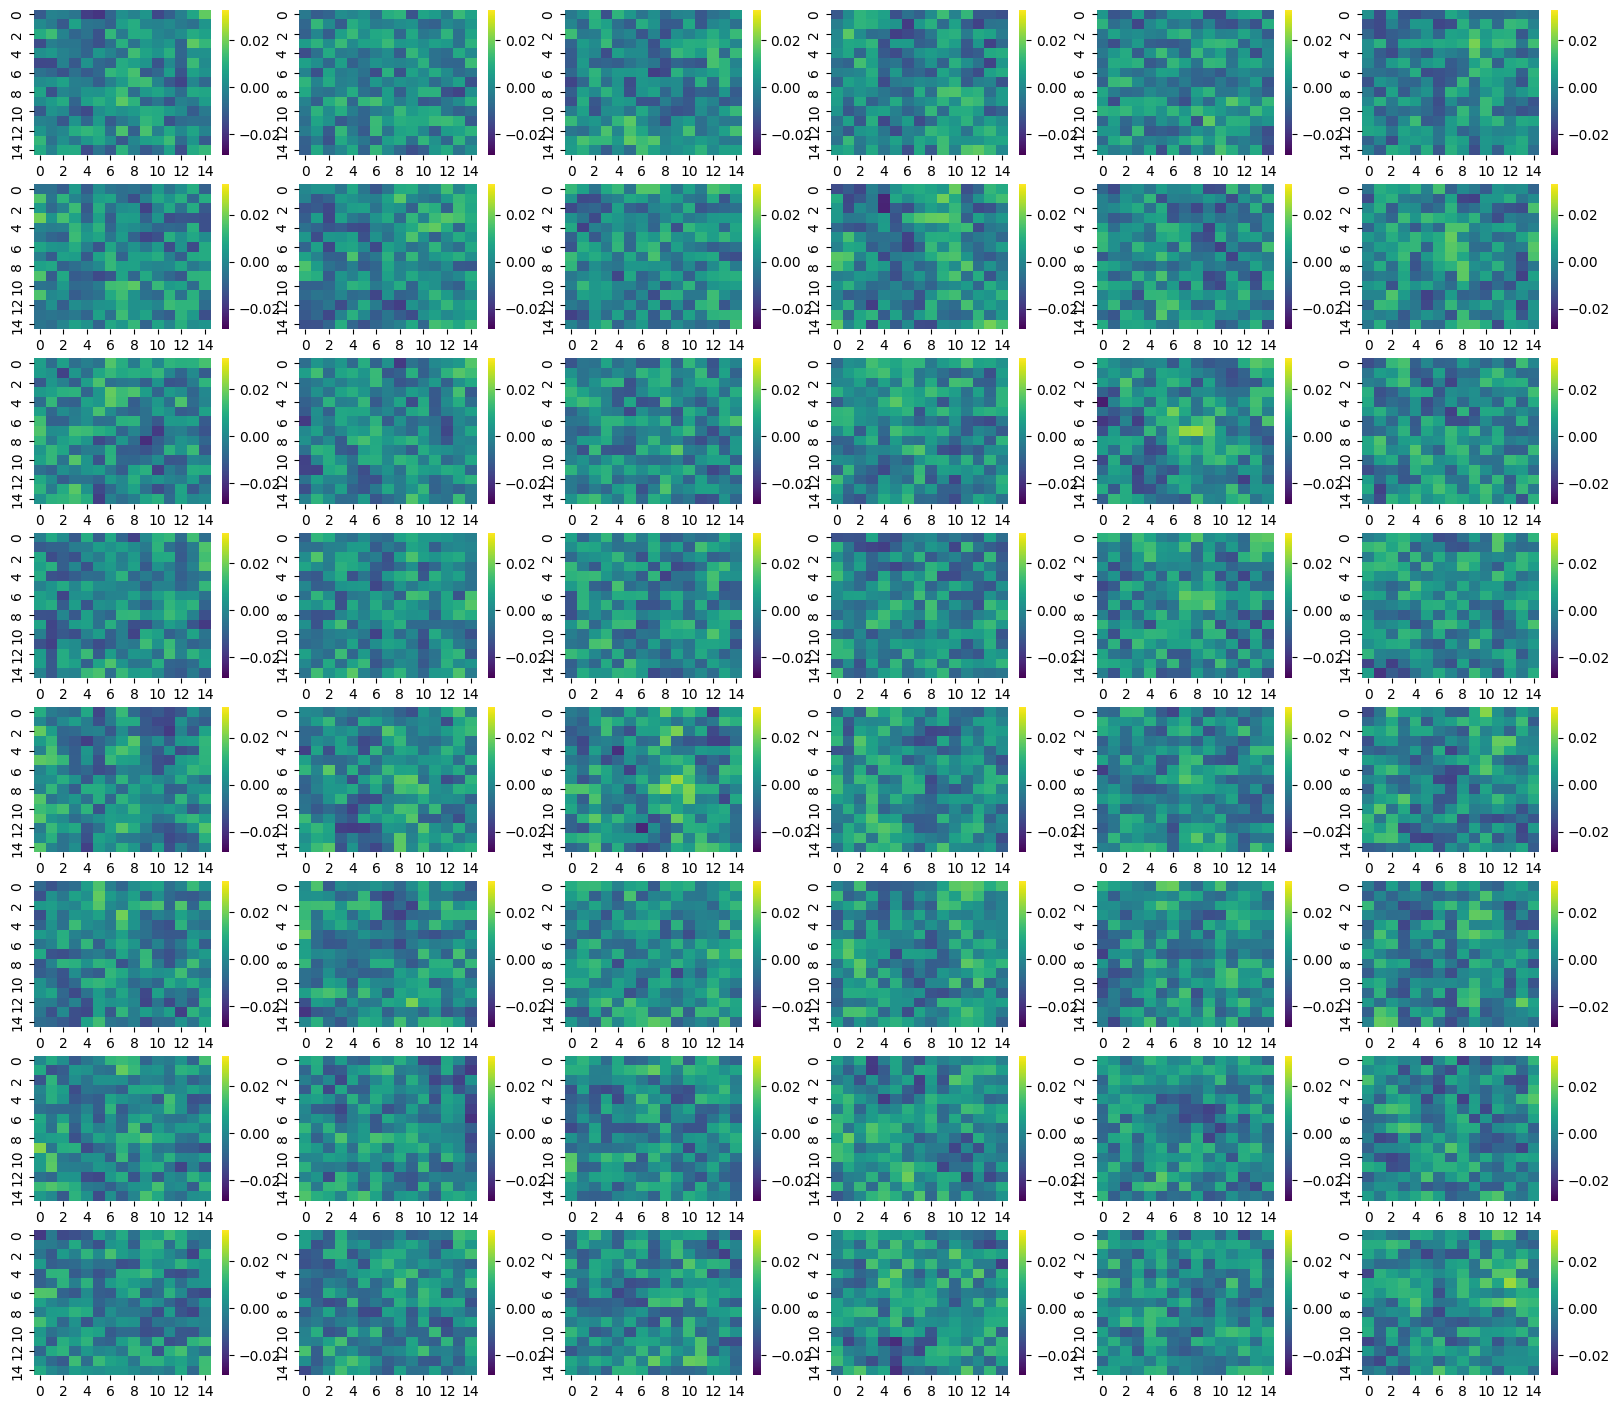


Visualisation de la face des 96 filtres de la couche 'layers.4.weight'


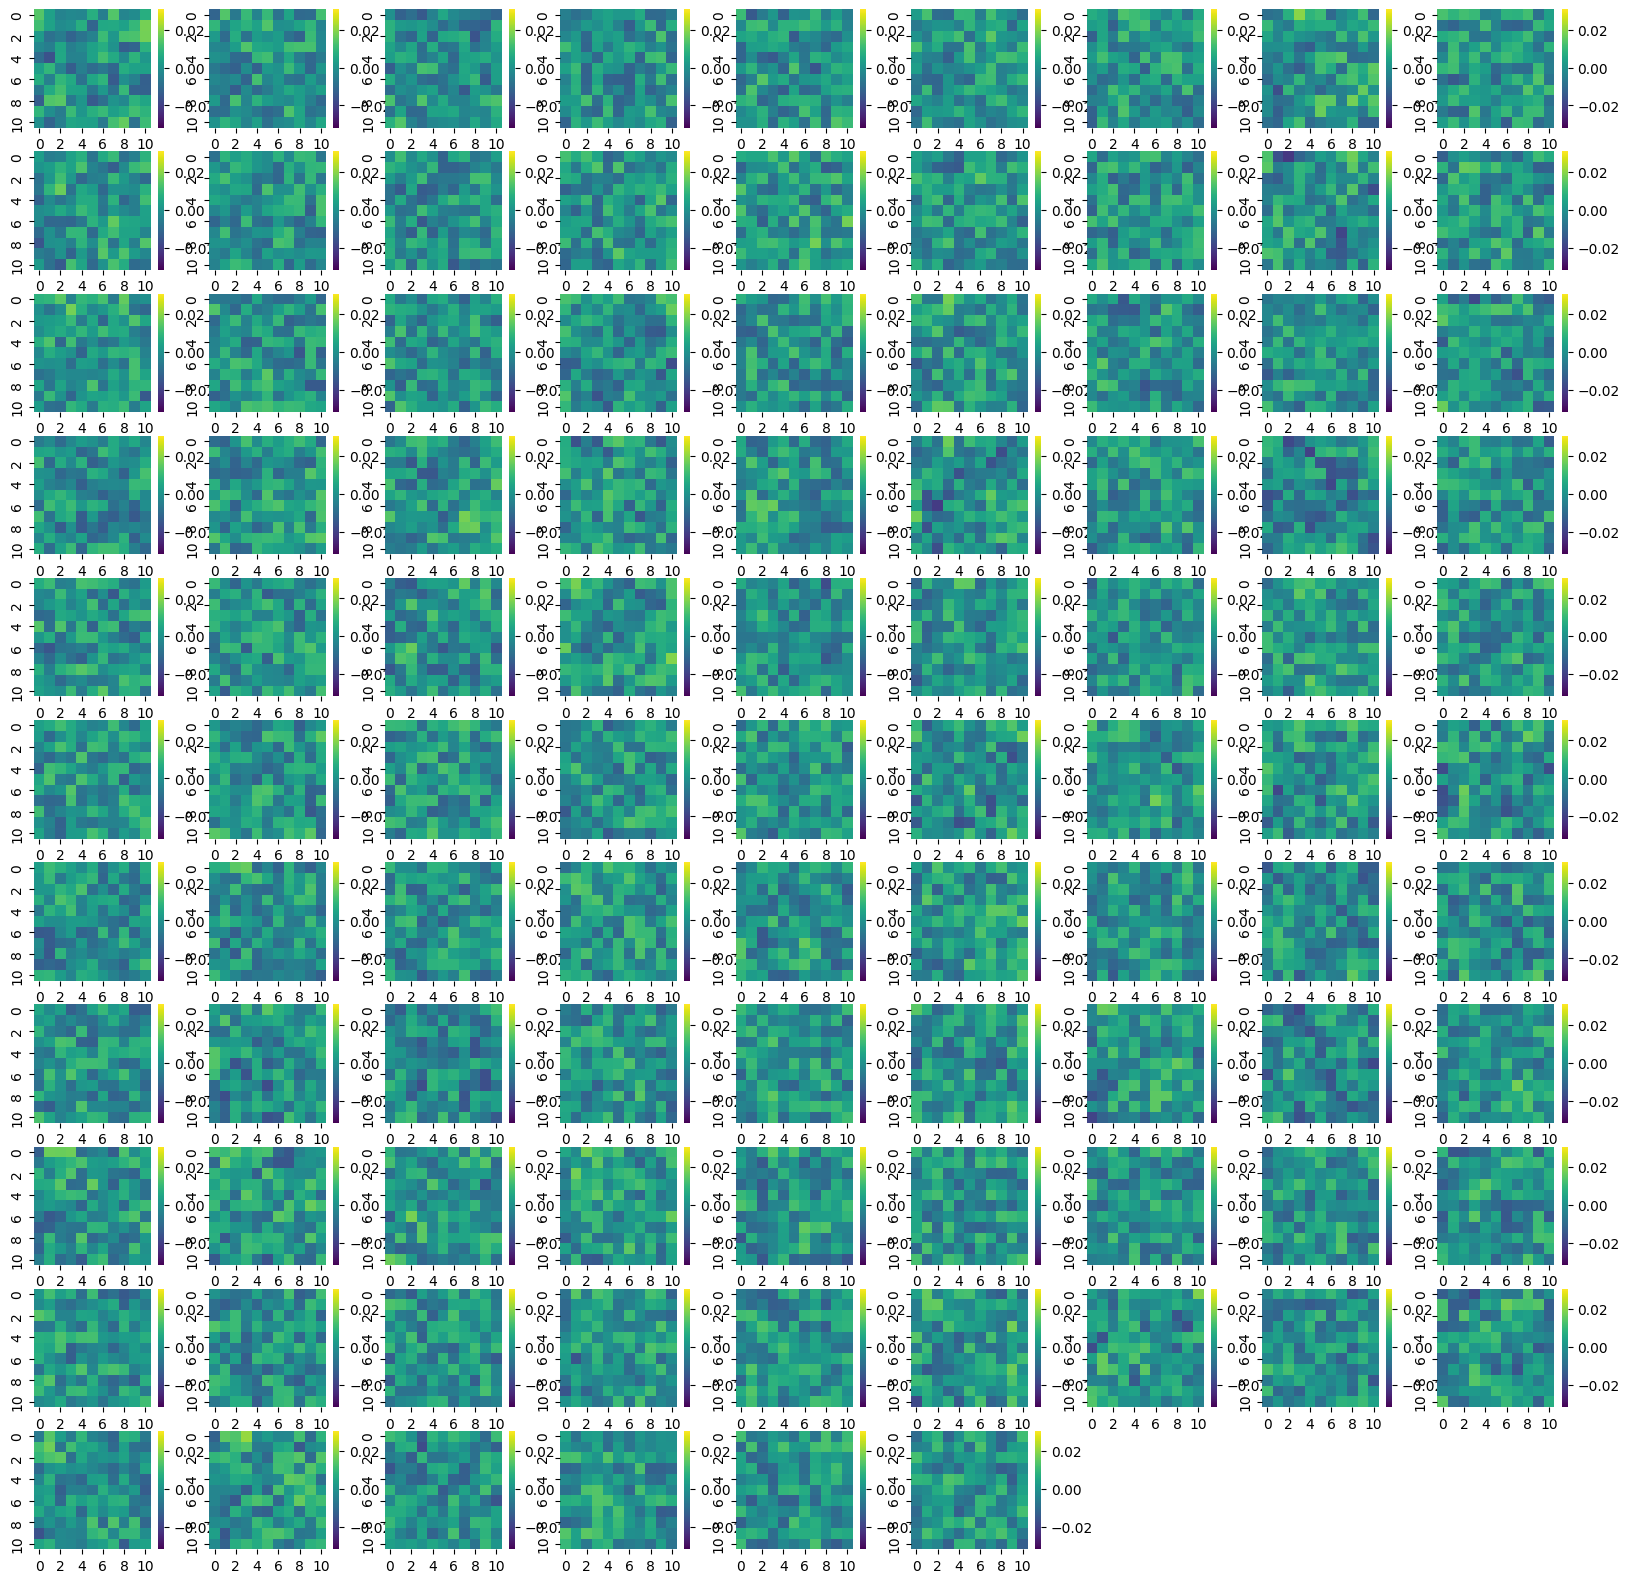

'state_dict' du modèle étudié :
layers.0.weight 	 torch.Size([20, 1, 15, 15])
layers.0.bias 	 torch.Size([20])
layers.2.weight 	 torch.Size([20, 20, 10, 10])
layers.2.bias 	 torch.Size([20])
layers.6.weight 	 torch.Size([40, 20, 5, 5])
layers.6.bias 	 torch.Size([40])
layers.8.weight 	 torch.Size([40, 40, 2, 2])
layers.8.bias 	 torch.Size([40])
layers.13.weight 	 torch.Size([50, 640])
layers.13.bias 	 torch.Size([50])
layers.16.weight 	 torch.Size([2, 50])
layers.16.bias 	 torch.Size([2])

Visualisation de la face des 20 filtres de la couche 'layers.0.weight'


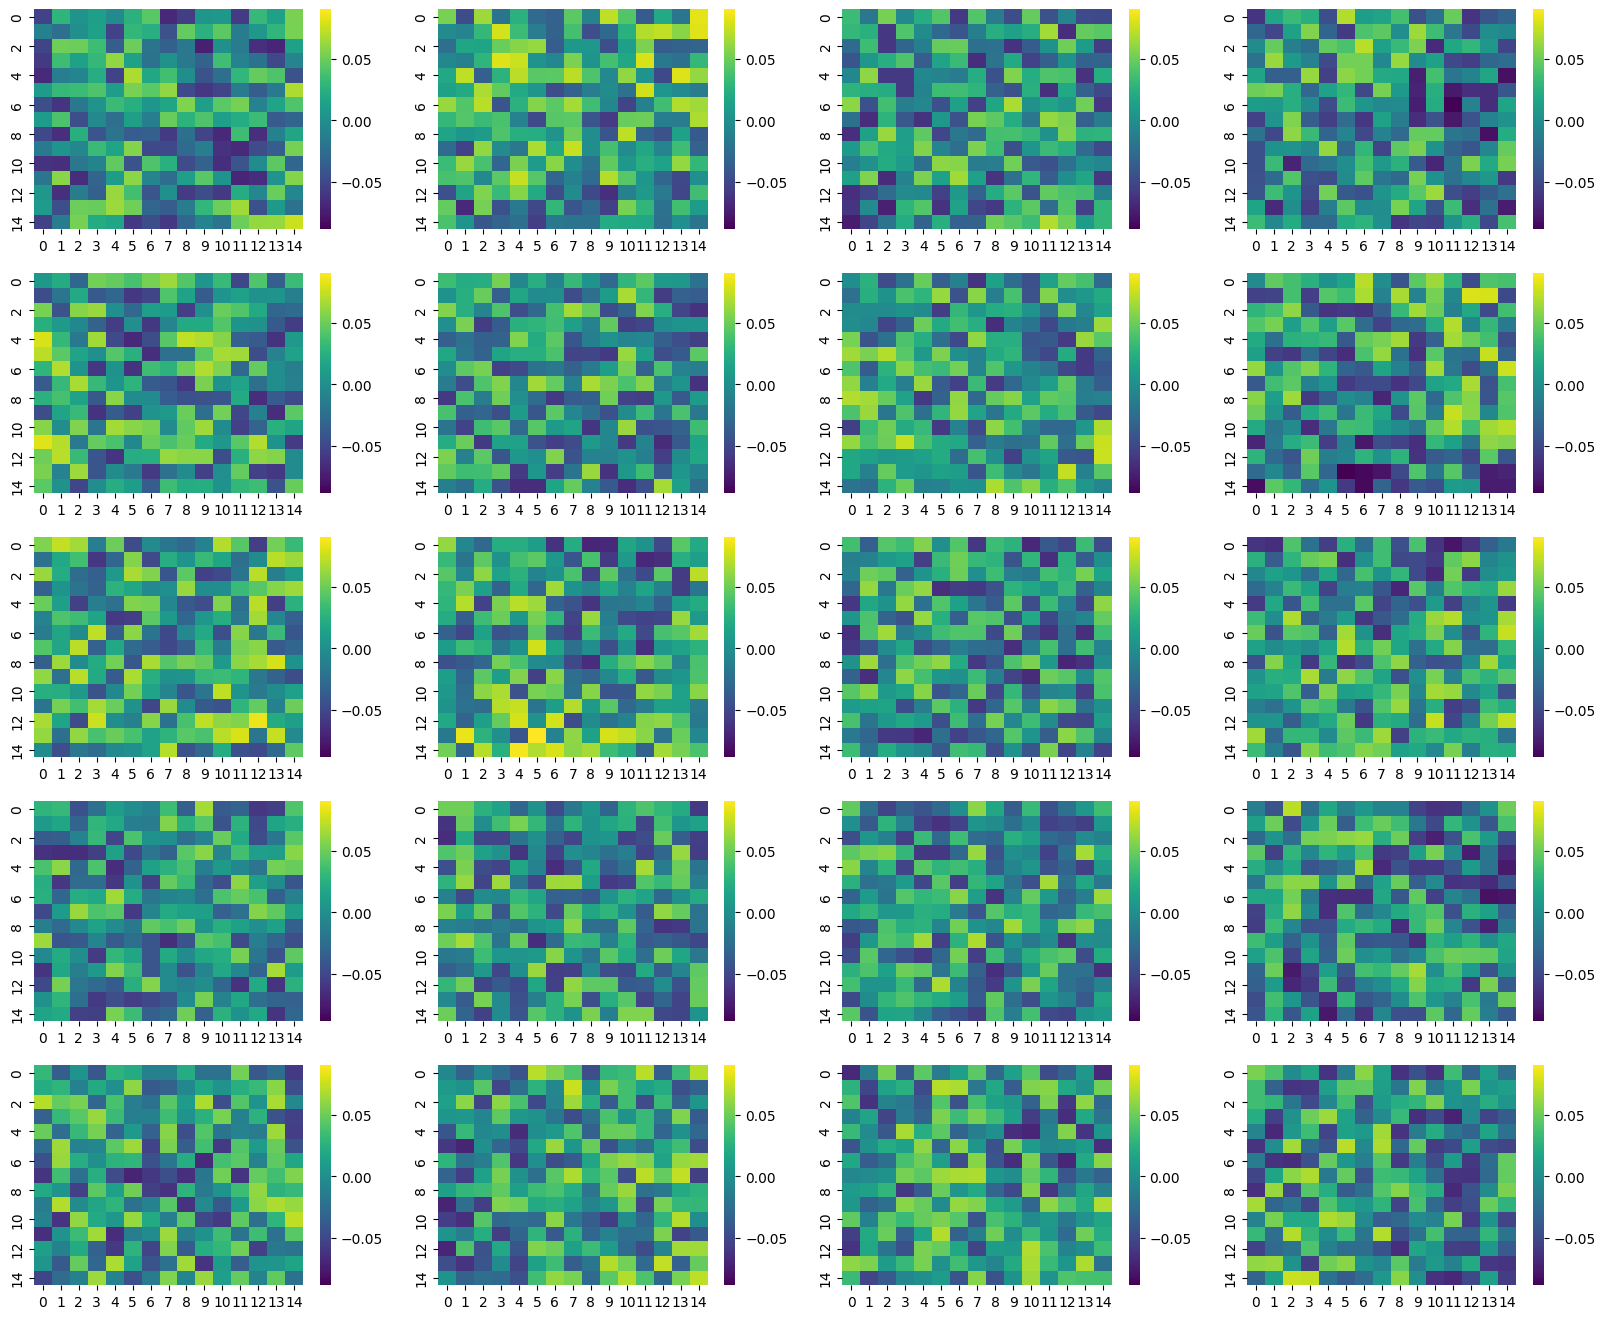


Visualisation de la face des 20 filtres de la couche 'layers.2.weight'


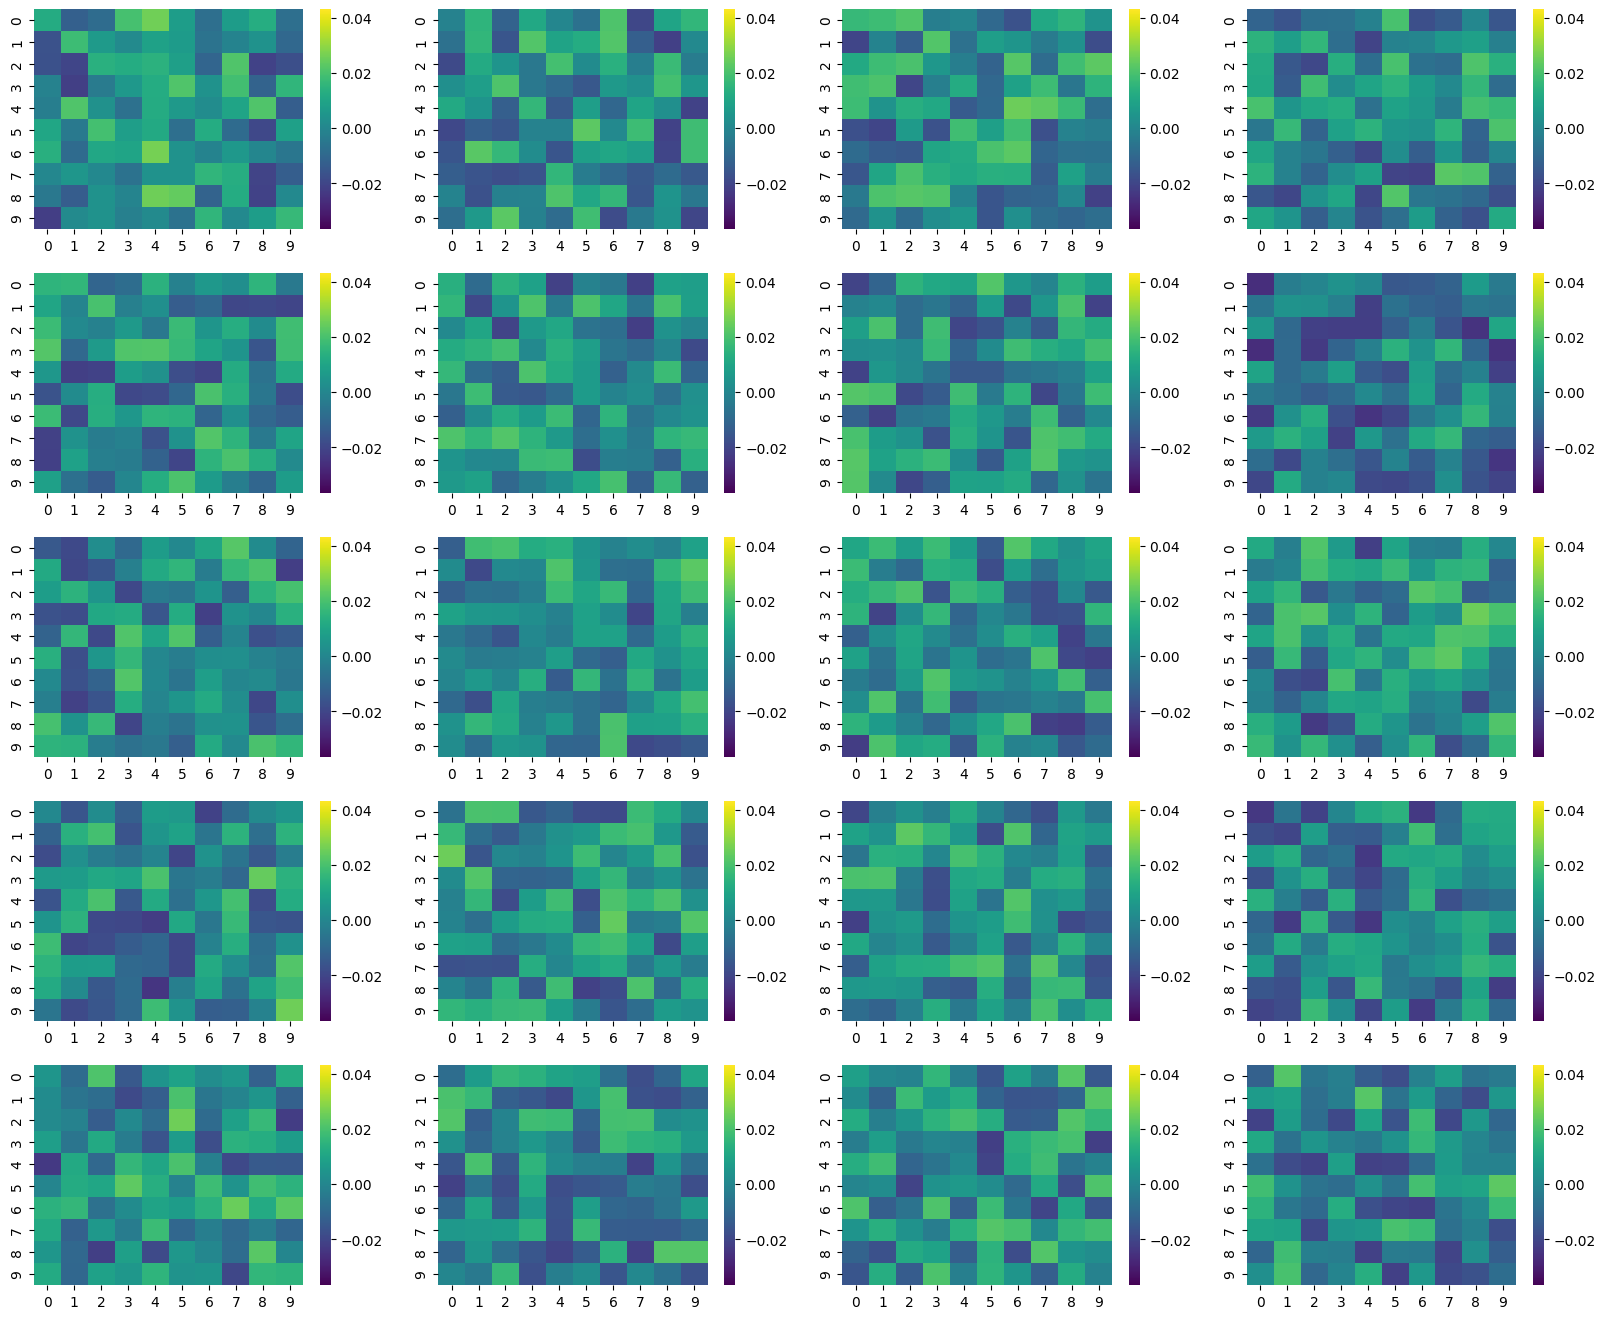


Visualisation de la face des 40 filtres de la couche 'layers.6.weight'


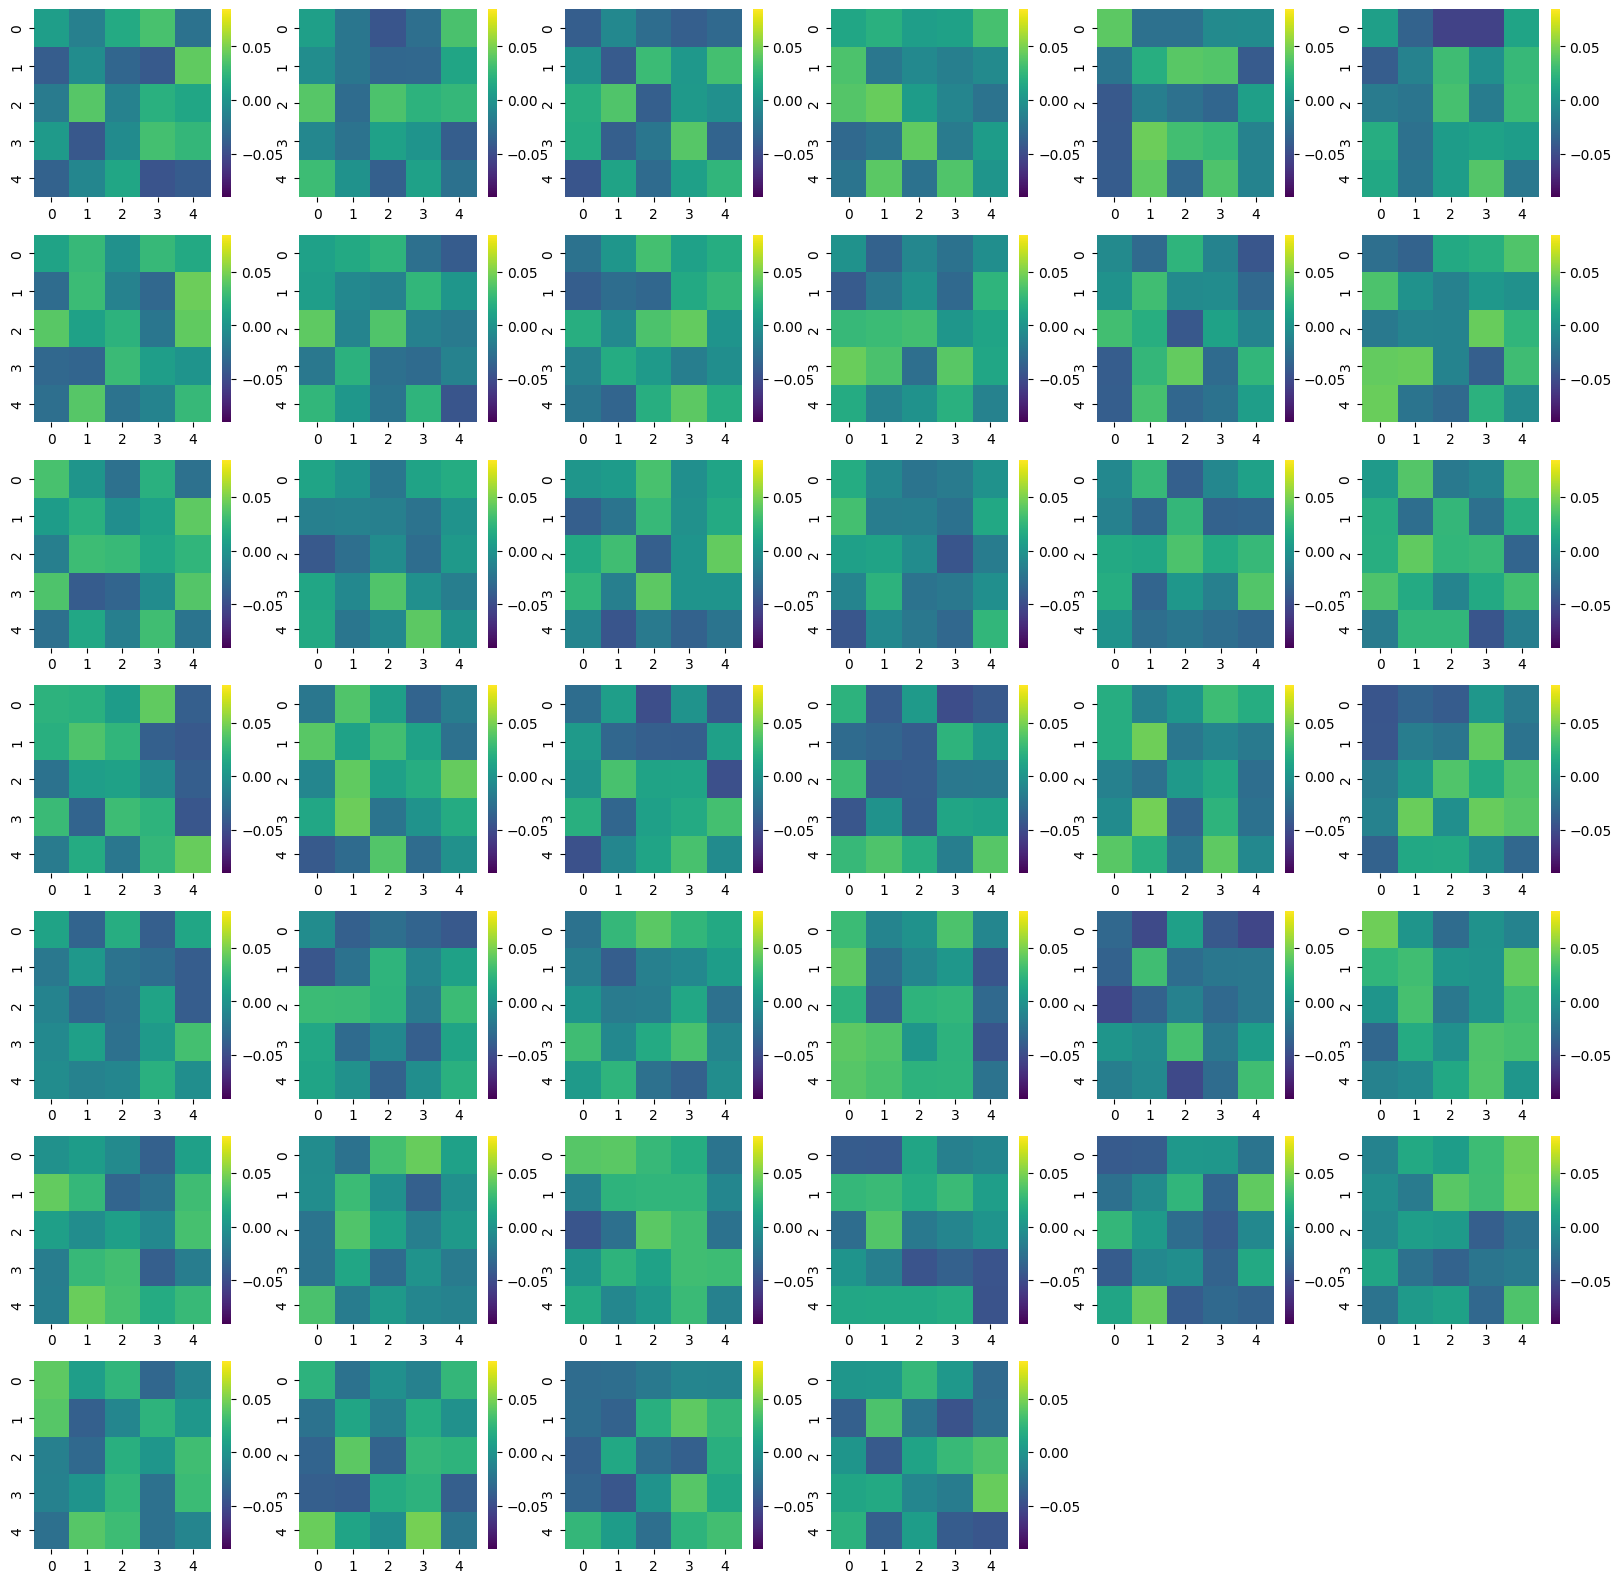


Visualisation de la face des 40 filtres de la couche 'layers.8.weight'


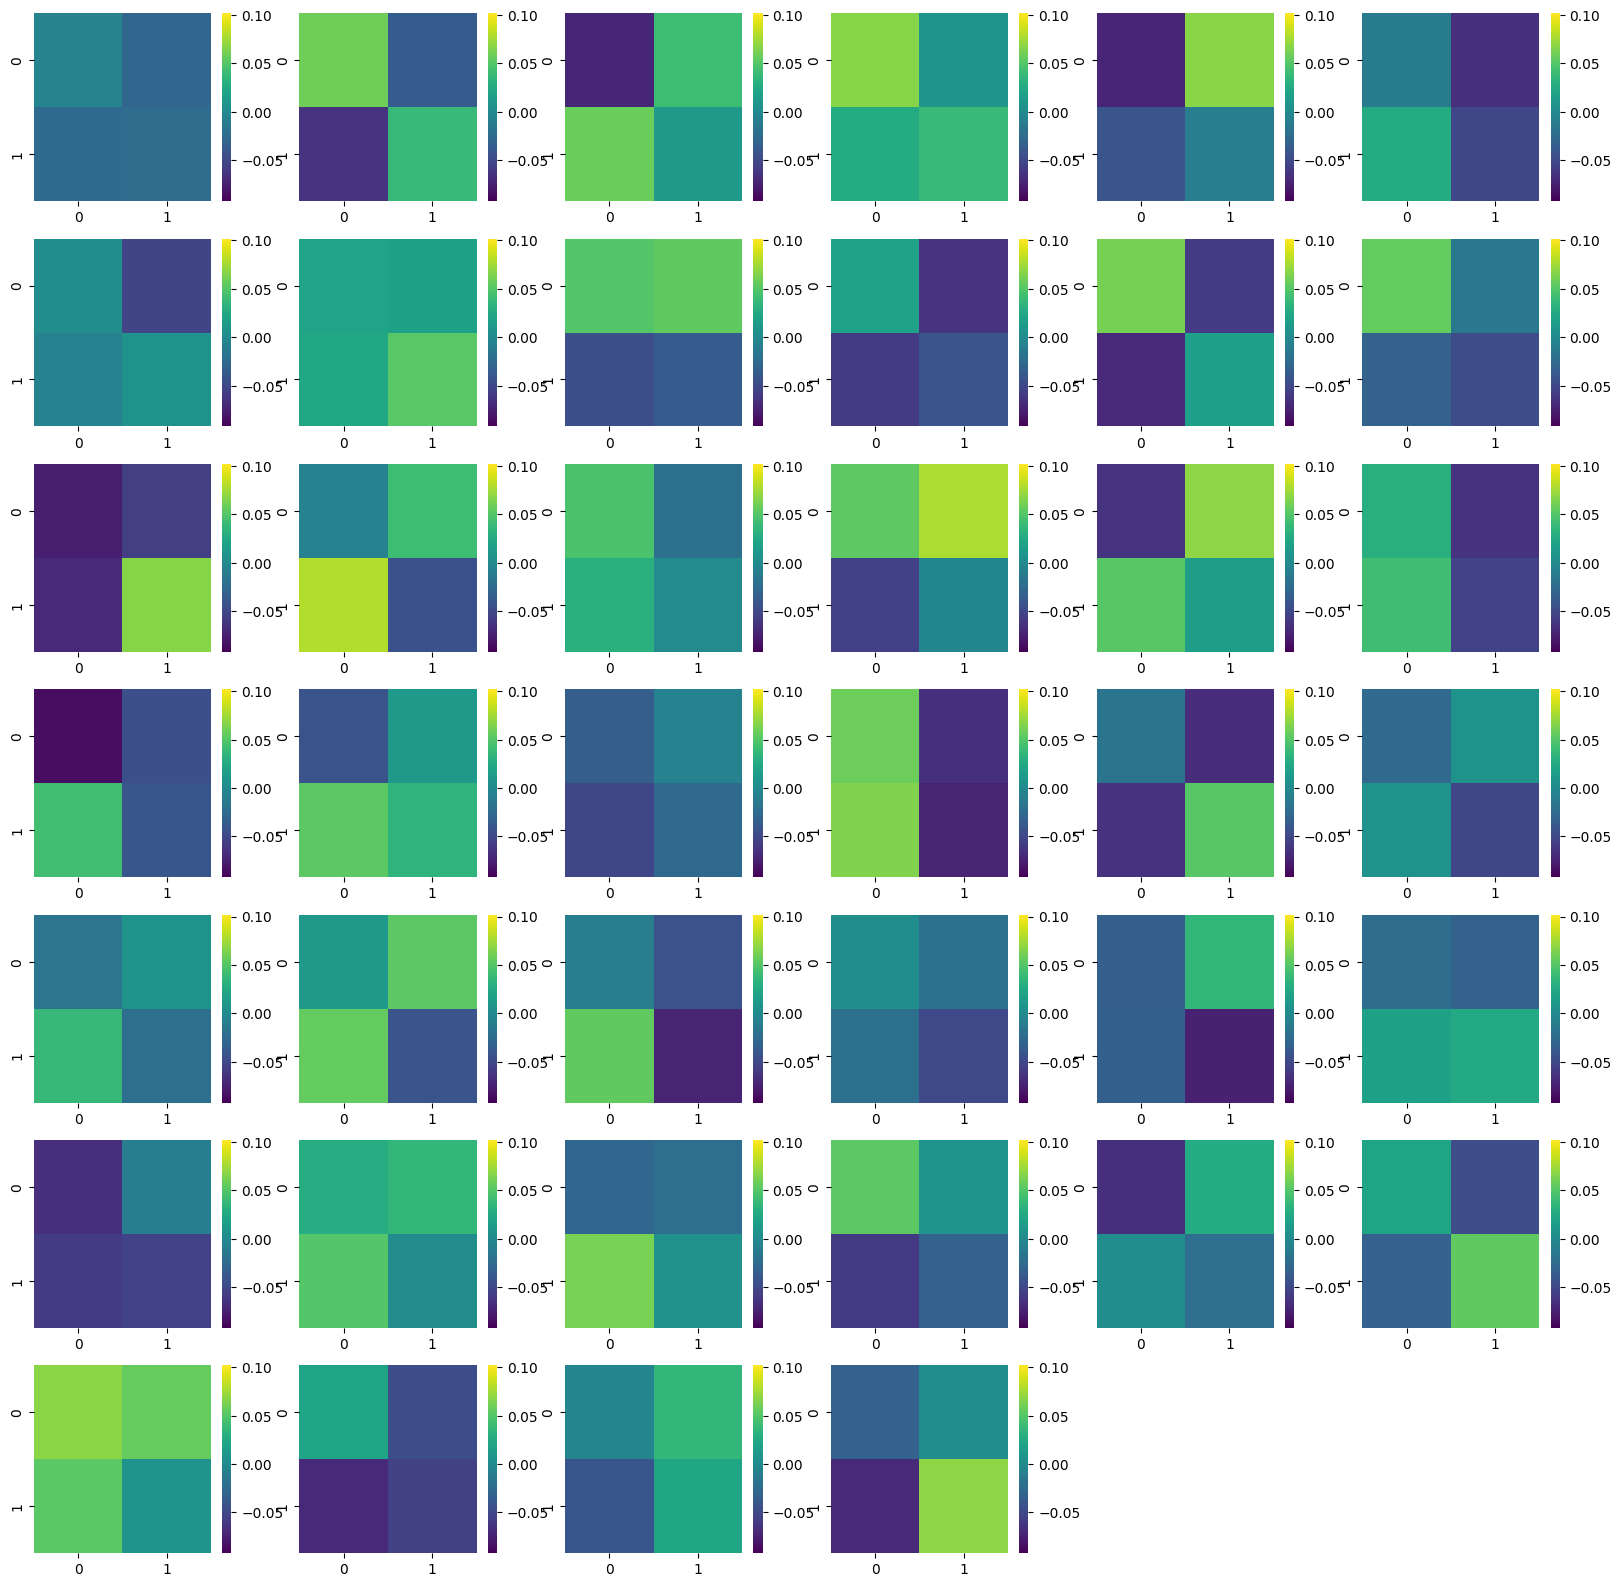

In [66]:
# Visualisation des paramètres optimisés du réseau

visualisation_parametres(model_A.state_dict(),['layers.0.weight','layers.2.weight','layers.4.weight'])
visualisation_parametres(model_B.state_dict(),['layers.0.weight','layers.2.weight','layers.6.weight','layers.8.weight'])


La visualisation des filtres doit permettre de visualiser les patternes récurrents dans les images de maçonnerie analysées. Le modèle A déploie 10 couches (dont 3 convolutions) tandis que le modèle B en a 18 (dont 4 convolutions) d'où la différence de temps de calcul...
L'affichage des résultats des convolutions ne laisse pas apparaitre de patterne clair. Cela est probablement due aux nombreuses images de natures différentes. Aussi, la taille des données est peut-être insuffisante pour pouvoir mettre en lumière les dits patternes.